<a href="https://colab.research.google.com/github/torcodex/House-Price-Predictor/blob/main/House_Price_Predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Load all the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.metrics import mean_squared_error, r2_score,mean_absolute_error
from scipy.stats import f_oneway
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression

In [ ]:
# Load the datasets
df = pd.read_csv('/content/AmesHousing.csv')
df

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,2926,923275080,80,RL,37.0,7937,Pave,NaN,IR1,Lvl,...,0,NaN,GdPrv,NaN,0,3,2006,WD,Normal,142500
2926,2927,923276100,20,RL,NaN,8885,Pave,NaN,IR1,Low,...,0,NaN,MnPrv,NaN,0,6,2006,WD,Normal,131000
2927,2928,923400125,85,RL,62.0,10441,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal,132000
2928,2929,924100070,20,RL,77.0,10010,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2006,WD,Normal,170000


In [ ]:
# Check for the null values
df.isna().sum().sum()

np.int64(15749)

In [ ]:
df.shape

(2930, 82)

In [ ]:
# Check for the duplicated values
df.duplicated().sum()

np.int64(0)

In [ ]:
dels = (df.isna().mean() * 100).sort_values(ascending=False)
dels[dels>0]

,0
Pool QC,99.556314
Misc Feature,96.382253
Alley,93.242321
Fence,80.477816
Mas Vnr Type,60.580205
Fireplace Qu,48.532423
Lot Frontage,16.723549
Garage Qual,5.426621
Garage Yr Blt,5.426621
Garage Cond,5.426621


In [ ]:
df.columns

Index(['Order', 'PID', 'MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area',
       'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities',
       'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1',
       'Condition 2', 'Bldg Type', 'House Style', 'Overall Qual',
       'Overall Cond', 'Year Built', 'Year Remod/Add', 'Roof Style',
       'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type',
       'Mas Vnr Area', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual',
       'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin SF 1',
       'BsmtFin Type 2', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF',
       'Heating', 'Heating QC', 'Central Air', 'Electrical', '1st Flr SF',
       '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath',
       'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr',
       'Kitchen AbvGr', 'Kitchen Qual', 'TotRms AbvGrd', 'Functional',
       'Fireplaces', 'Fireplace Qu', 'Garage Type', 'Garage Yr Blt',
      

In [ ]:
df.drop(columns=['Pool QC','Order','Misc Feature','Alley','Fence','Mas Vnr Type','Fireplace Qu'], inplace=True)

In [ ]:
# Check for the wrong entries
df[df['SalePrice']<0]

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Lot Shape,Land Contour,Utilities,Lot Config,...,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice


In [ ]:
no_garage = df["Garage Type"].isna()
no_garage.sum()

np.int64(157)

In [ ]:
df['SalePrice'].isna().sum()

np.int64(0)

In [ ]:
garage_categorical = [
    "Garage Type",
    "Garage Finish",
    "Garage Qual",
    "Garage Cond"
]

for col in garage_categorical:
    df.loc[no_garage, col] = "None"

In [ ]:
garage_numeric = [
    "Garage Cars",
    "Garage Area"
]

for col in garage_numeric:
    df.loc[no_garage, col] = 0

In [ ]:
# Identify houses without a basement
no_basement = df["Total Bsmt SF"].eq(0)
no_basement.sum()

np.int64(79)

In [ ]:
basement_numeric = [
    "BsmtFin SF 1",
    "BsmtFin SF 2",
    "Bsmt Unf SF",
    "Total Bsmt SF",
    "Bsmt Full Bath",
    "Bsmt Half Bath"
]

for col in basement_numeric:
    df.loc[no_basement, col] = (
        df.loc[no_basement, col].fillna(0)
    )

In [ ]:
nulls = df.isna().sum()
nulls[nulls>0]

,0
Lot Frontage,490
Mas Vnr Area,23
Bsmt Qual,80
Bsmt Cond,80
Bsmt Exposure,83
BsmtFin Type 1,80
BsmtFin SF 1,1
BsmtFin Type 2,81
BsmtFin SF 2,1
Bsmt Unf SF,1


In [ ]:
df[df['Garage Qual'].isna()][['Garage Cond', 'Garage Area','Garage Qual','Garage Cars','Garage Finish']]

,Garage Cond,Garage Area,Garage Qual,Garage Cars,Garage Finish
1356,NaN,360.0,NaN,1.0,NaN
2236,NaN,NaN,NaN,NaN,NaN


In [ ]:
df.dropna(subset=['Electrical','Garage Yr Blt'], inplace=True)

In [ ]:
basement_categorical = [
    "Bsmt Qual",
    "Bsmt Cond",
    "Bsmt Exposure",
    "BsmtFin Type 1",
    "BsmtFin Type 2"
]

for col in basement_categorical:
    df.loc[no_basement, col] = "None"

In [ ]:
df['BsmtFin Type 2'].unique()

array(['Unf', 'LwQ', 'BLQ', 'Rec', 'None', 'GLQ', 'ALQ', nan],
      dtype=object)

In [ ]:
df['BsmtFin Type 2'] = df['BsmtFin Type 2'].fillna('None')

In [ ]:
# Fill remaining missing values in 'Bsmt Exposure' with 'None'
df['Bsmt Exposure'] = df['Bsmt Exposure'].fillna('No')

# Verify that there are no remaining missing values in this column
print("Missing values in Bsmt Exposure:", df['Bsmt Exposure'].isna().sum())

Missing values in Bsmt Exposure: 0


In [ ]:
# 1. Define the specified columns we want to check
target_cols = ['Garage Cond', 'Garage Area', 'Garage Qual', 'Garage Cars', 'Garage Finish']

# 2. Check if each value is either NaN or the string 'None'
is_empty = df[target_cols].isna() | (df[target_cols] == 'None') | (df[target_cols] == 0)

# 3. Create a boolean mask where ALL specified columns are empty/zero
mask = is_empty.all(axis=1)

# 4. Identify the rest of the garage columns in the dataframe
all_garage_cols = [col for col in df.columns if 'Garage' in col]
rest_garage_cols = [col for col in all_garage_cols if col not in target_cols]

# 5. Fill the remaining garage columns with 'None' for these rows
# We first cast them to object to avoid dtype conflict warnings
for col in rest_garage_cols:
    df[col] = df[col].astype(object)
    df.loc[mask, col] = 'None'

# Display a sample of the updated rows
df[mask][all_garage_cols].head()

,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond


In [ ]:
df["Mas Vnr Area"] = df["Mas Vnr Area"].fillna(0)

print(df["Mas Vnr Area"].isnull().sum())

0


In [ ]:
# 3. Handle missing values for Garages
no_garage = df["Garage Type"].isna()
garage_categorical = ["Garage Type", "Garage Finish", "Garage Qual", "Garage Cond"]
for col in garage_categorical:
    df[col] = df[col].astype(str).replace('nan', 'None')

garage_numeric = ["Garage Cars", "Garage Area"]
for col in garage_numeric:
    df[col] = df[col].fillna(0)


In [ ]:
# Convert Lot Frontage back to numeric, coercing strings like 'None' back to NaN
df['Lot Frontage'] = pd.to_numeric(df['Lot Frontage'], errors='coerce')

# Now calculate the median group-wise
df["Lot Frontage"] = df["Lot Frontage"].fillna(
    df.groupby("Neighborhood")["Lot Frontage"]
      .transform("median")
)

df["Lot Frontage"] = df["Lot Frontage"].fillna(df["Lot Frontage"].median())

# Check remaining missing values
print(df["Lot Frontage"].isnull().sum())

0


In [ ]:
# 4. Handle missing values for Basements
no_basement = df["Total Bsmt SF"].eq(0) | df["Total Bsmt SF"].isna()
basement_numeric = ["BsmtFin SF 1", "BsmtFin SF 2", "Bsmt Unf SF", "Total Bsmt SF", "Bsmt Full Bath", "Bsmt Half Bath"]
for col in basement_numeric:
    df[col] = df[col].fillna(0)

# 6. Verify numerical columns are back to numeric and show correlation matrix
correlation_matrix = df.corr(numeric_only=True)
display(correlation_matrix.round(2))

,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
PID,1.00,-0.03,-0.08,0.05,-0.25,0.12,-0.33,-0.15,-0.22,-0.09,...,-0.03,-0.07,0.15,-0.02,-0.02,-0.00,-0.01,-0.05,0.00,-0.22
MS SubClass,-0.03,1.00,-0.41,-0.20,0.07,-0.09,0.08,0.06,0.01,-0.06,...,-0.01,-0.01,-0.04,-0.04,-0.05,-0.00,-0.04,0.00,-0.02,-0.07
Lot Frontage,-0.08,-0.41,1.00,0.38,0.19,-0.05,0.11,0.08,0.22,0.21,...,0.12,0.17,0.01,0.03,0.07,0.16,0.04,0.01,-0.01,0.35
Lot Area,0.05,-0.20,0.38,1.00,0.08,-0.04,0.01,0.01,0.12,0.19,...,0.15,0.10,0.03,0.02,0.05,0.09,0.07,0.00,-0.02,0.25
Overall Qual,-0.25,0.07,0.19,0.08,1.00,-0.14,0.60,0.57,0.42,0.27,...,0.24,0.31,-0.13,0.01,0.03,0.03,0.01,0.03,-0.01,0.80
Overall Cond,0.12,-0.09,-0.05,-0.04,-0.14,1.00,-0.41,0.01,-0.14,-0.06,...,0.01,-0.09,0.08,0.04,0.04,-0.02,0.04,-0.00,0.04,-0.13
Year Built,-0.33,0.08,0.11,0.01,0.60,-0.41,1.00,0.63,0.30,0.27,...,0.22,0.23,-0.36,0.02,-0.06,-0.00,-0.01,0.01,-0.00,0.55
Year Remod/Add,-0.15,0.06,0.08,0.01,0.57,0.01,0.63,1.00,0.19,0.14,...,0.21,0.26,-0.22,0.03,-0.06,-0.01,0.00,0.03,0.04,0.53
Mas Vnr Area,-0.22,0.01,0.22,0.12,0.42,-0.14,0.30,0.19,1.00,0.29,...,0.16,0.14,-0.11,0.01,0.06,0.00,0.05,-0.01,-0.01,0.50
BsmtFin SF 1,-0.09,-0.06,0.21,0.19,0.27,-0.06,0.27,0.14,0.29,1.00,...,0.22,0.13,-0.10,0.05,0.09,0.08,0.10,0.00,0.02,0.42


In [ ]:
(df.corr(numeric_only=True)['SalePrice'].sort_values(ascending=False))>0.45

,SalePrice
SalePrice,True
Overall Qual,True
Gr Liv Area,True
Garage Cars,True
Garage Area,True
Total Bsmt SF,True
1st Flr SF,True
Year Built,True
Full Bath,True
Year Remod/Add,True


In [ ]:
df.drop(columns={'PID'},inplace=True)

In [ ]:
x = df.drop(columns=['SalePrice'])
y = df['SalePrice']

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
numeric_features = x_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# MS SubClass is a building-class code, not a continuous measurement.
if "MS SubClass" in numeric_features:
    numeric_features.remove("MS SubClass")

print("Number of numerical features:", len(numeric_features))

Number of numerical features: 34


In [ ]:
# Combine numerical training features with target
corr_data = x_train[numeric_features].copy()

corr_data["SalePrice"] = y_train

# Calculate correlations
correlation = corr_data.corr()["SalePrice"]

# Remove target and sort
correlation = (
    correlation
    .drop("SalePrice")
    .sort_values(ascending=False)
)*100

display(correlation.to_frame("Correlation"))

,Correlation
Overall Qual,79.187406
Gr Liv Area,71.631175
Garage Cars,63.481592
Total Bsmt SF,62.412578
Garage Area,61.472142
1st Flr SF,61.183075
Full Bath,55.296300
Year Built,55.114424
Year Remod/Add,52.834595
TotRms AbvGrd,49.860982


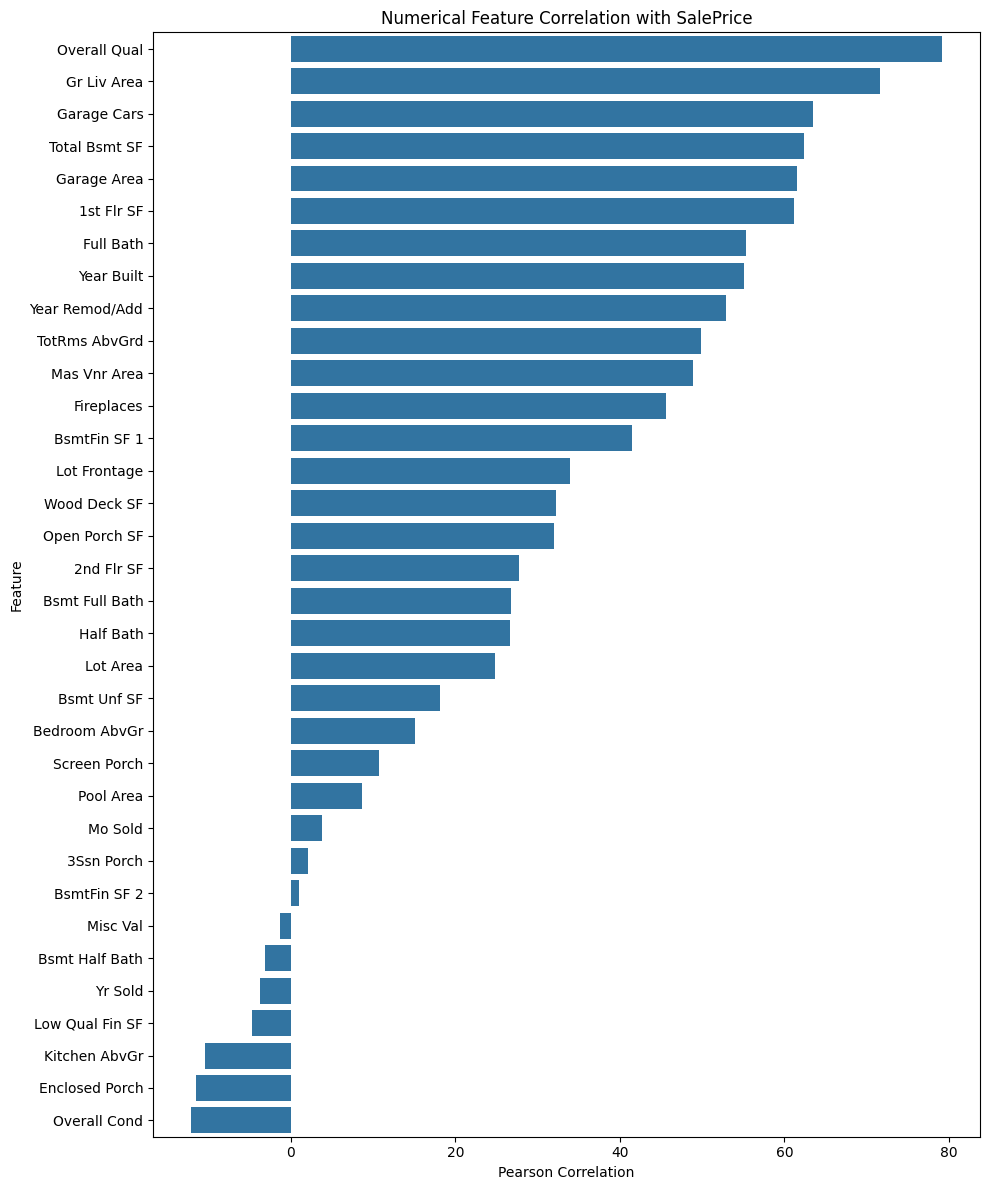

In [ ]:
plt.figure(figsize=(10, 12))

sns.barplot(
    x=correlation.values,
    y=correlation.index
)

plt.title("Numerical Feature Correlation with SalePrice")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

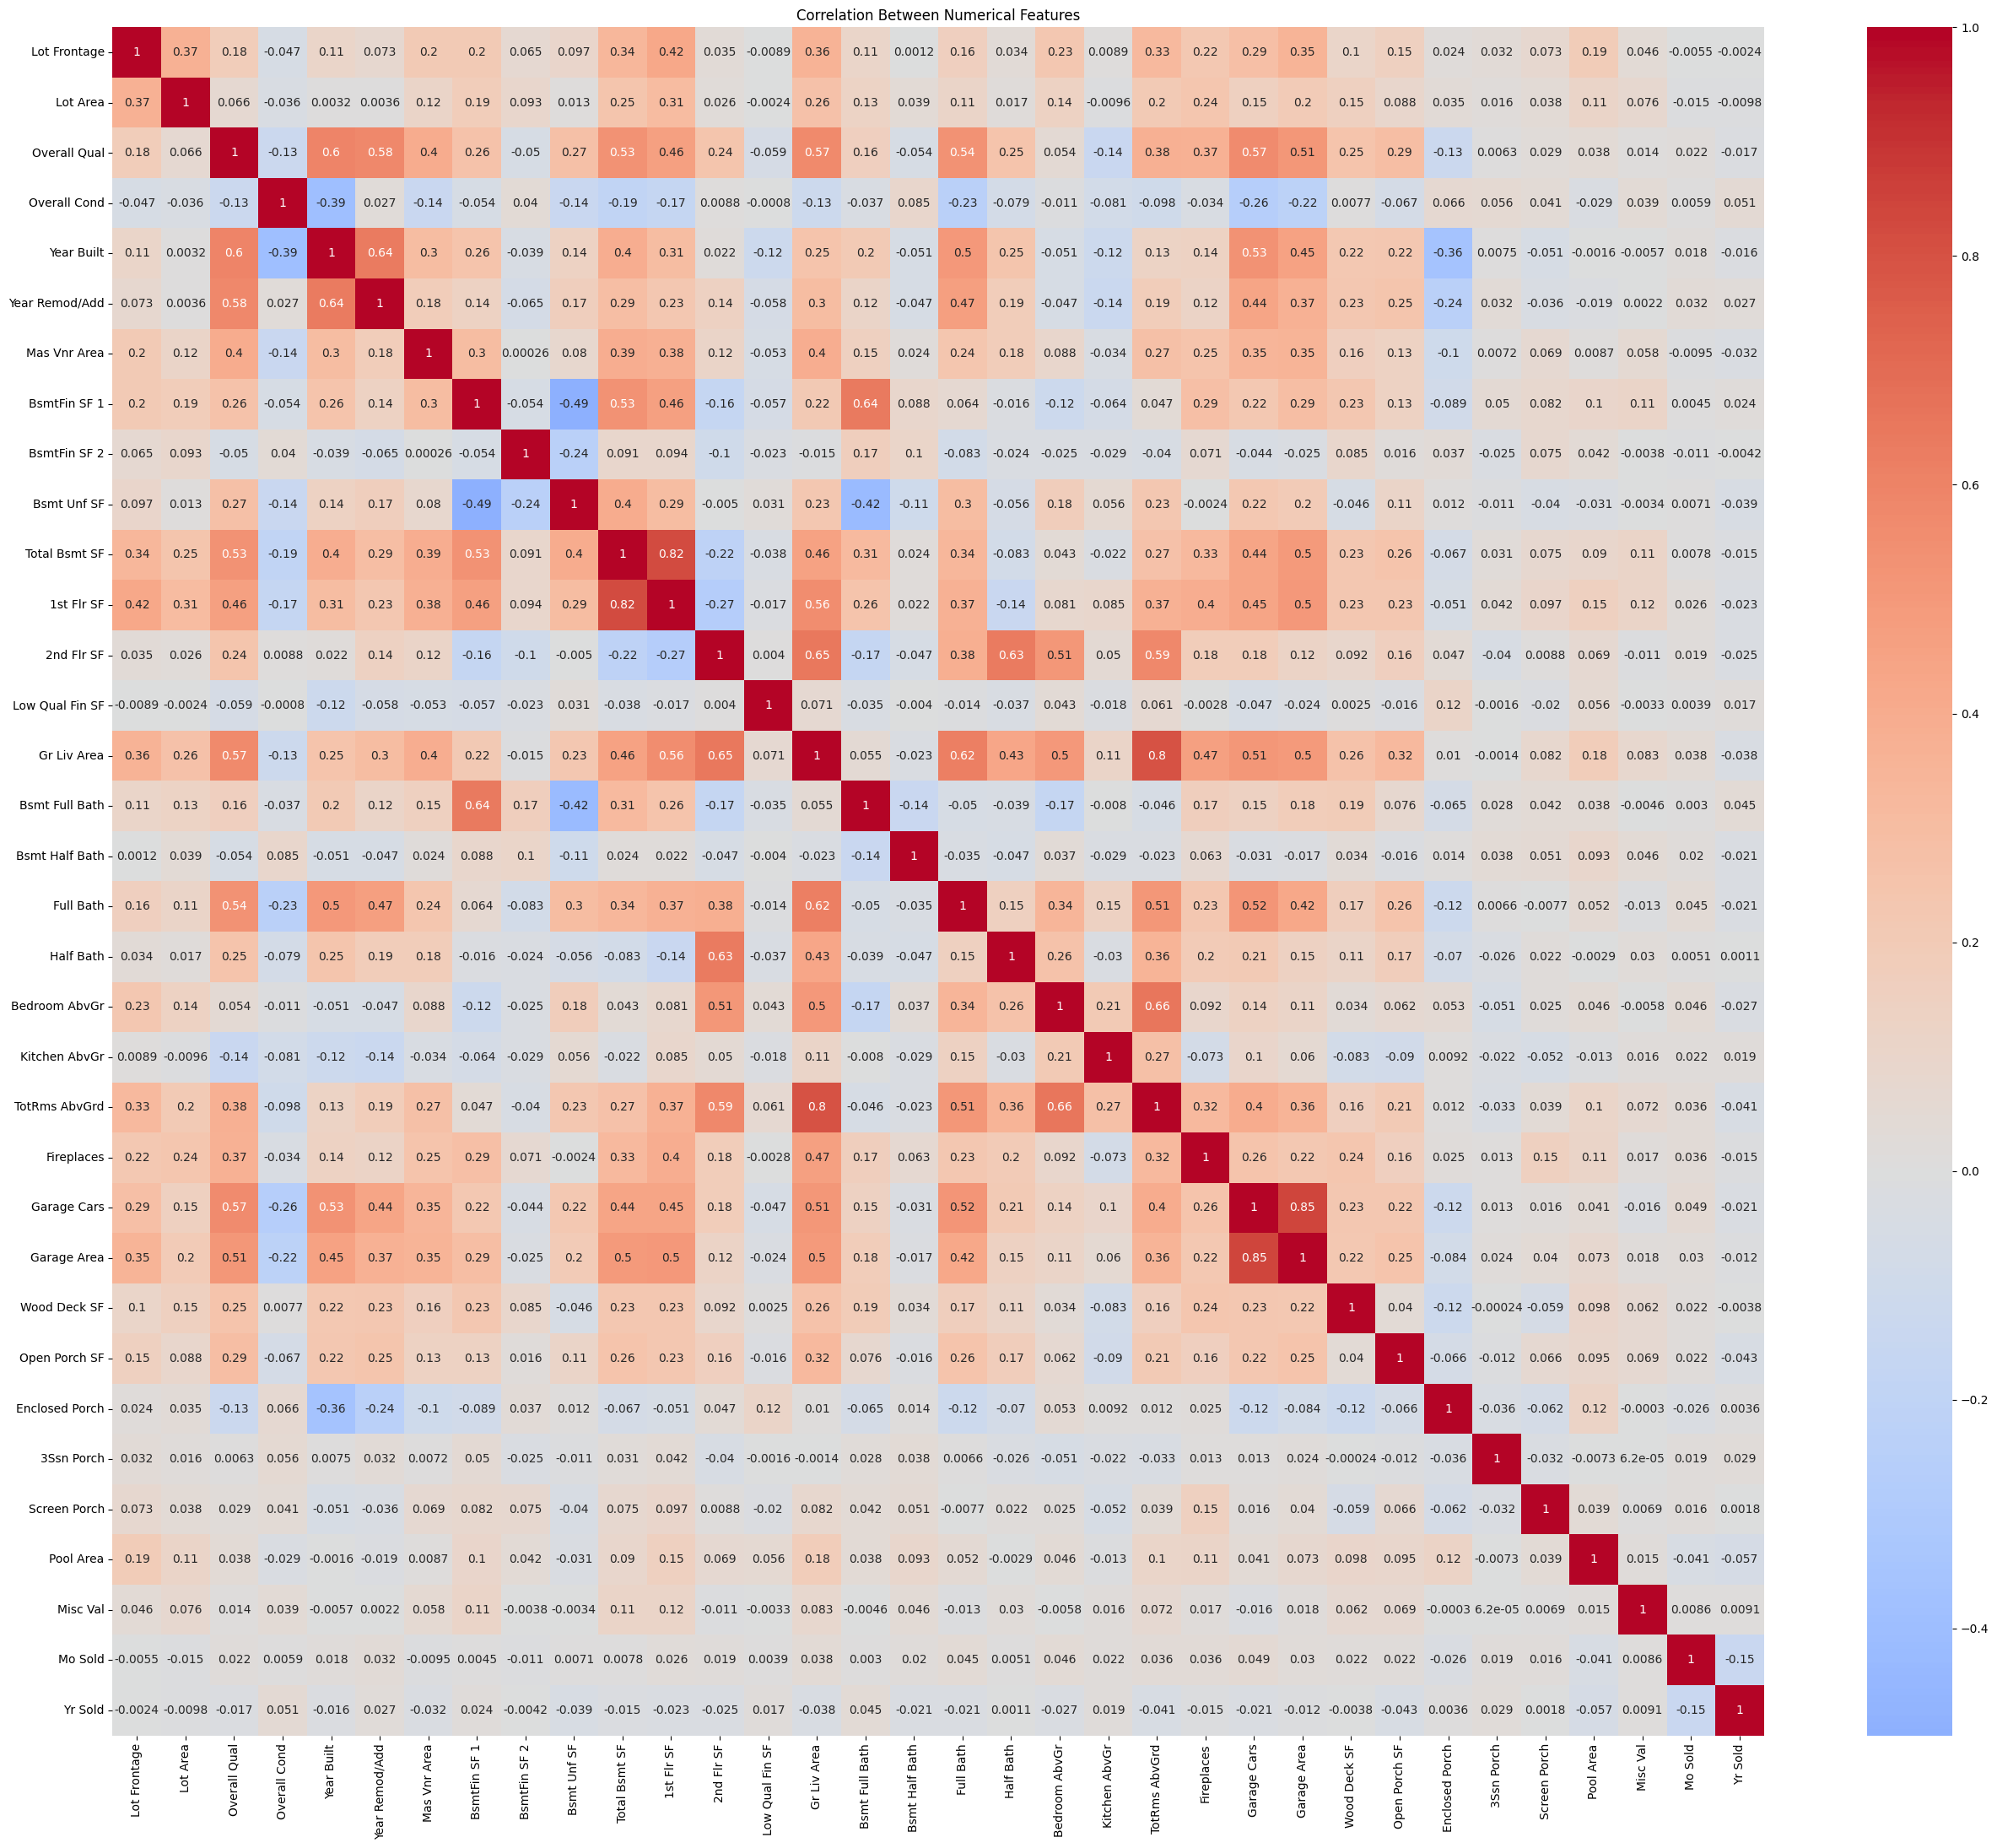

In [ ]:
feature_corr = x_train[numeric_features].corr()

plt.figure(figsize=(26, 22))

sns.heatmap(
    feature_corr,
    cmap="coolwarm",
    center=0,
    annot=True
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

In [ ]:
upper_triangle = feature_corr.where(
    np.triu(
        np.ones(feature_corr.shape),
        k=1
    ).astype(bool)
)

high_corr_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

high_corr_pairs["Correlation"] = (
    high_corr_pairs["Correlation"].abs()
)

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["Correlation"] >= 0.80
].sort_values(
    by="Correlation",
    ascending=False
)

display(high_corr_pairs)

,Feature 1,Feature 2,Correlation
506,Garage Cars,Garage Area,0.845039
285,Total Bsmt SF,1st Flr SF,0.820275
377,Gr Liv Area,TotRms AbvGrd,0.800865


In [ ]:
neighborhood_analysis = (
    df.groupby("Neighborhood")["SalePrice"]
      .agg(["mean", "median", "count"])
      .sort_values("median", ascending=False)
)

display(neighborhood_analysis)

,mean,median,count
Neighborhood,,,
StoneBr,324229.196078,319000.0,51
NridgHt,322018.265060,317750.0,166
NoRidge,330319.126761,302000.0,71
GrnHill,280000.000000,280000.0,2
Veenker,248314.583333,250250.0,24
Timber,247713.619718,232500.0,71
Somerst,229707.324176,225500.0,182
Crawfor,207550.834951,200624.0,103
CollgCr,202392.139623,200000.0,265


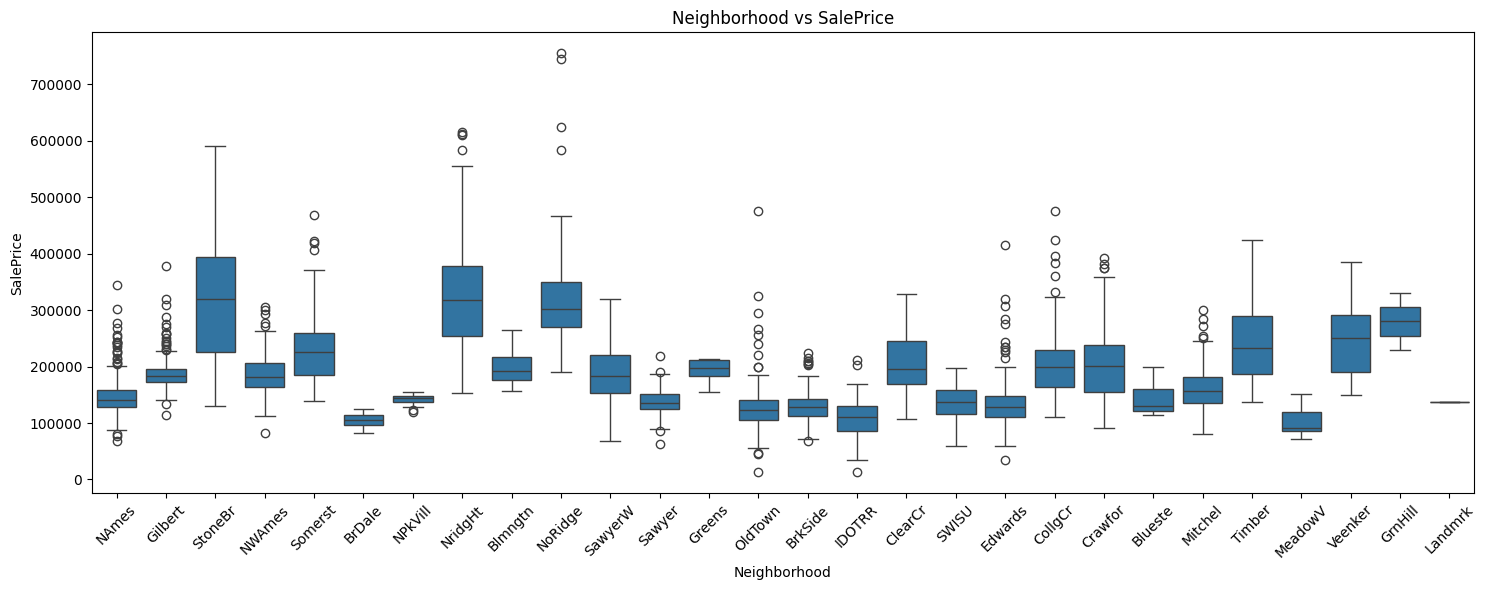

In [ ]:
plt.figure(figsize=(15, 6))

sns.boxplot(
    data=df,
    x="Neighborhood",
    y="SalePrice"
)

plt.xticks(rotation=45)
plt.title("Neighborhood vs SalePrice")
plt.tight_layout()
plt.show()

In [ ]:
categorical_features = x_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print(categorical_features)

['MS Zoning', 'Street', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'House Style', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin Type 2', 'Heating', 'Heating QC', 'Central Air', 'Electrical', 'Kitchen Qual', 'Functional', 'Garage Type', 'Garage Yr Blt', 'Garage Finish', 'Garage Qual', 'Garage Cond', 'Paved Drive', 'Sale Type', 'Sale Condition']


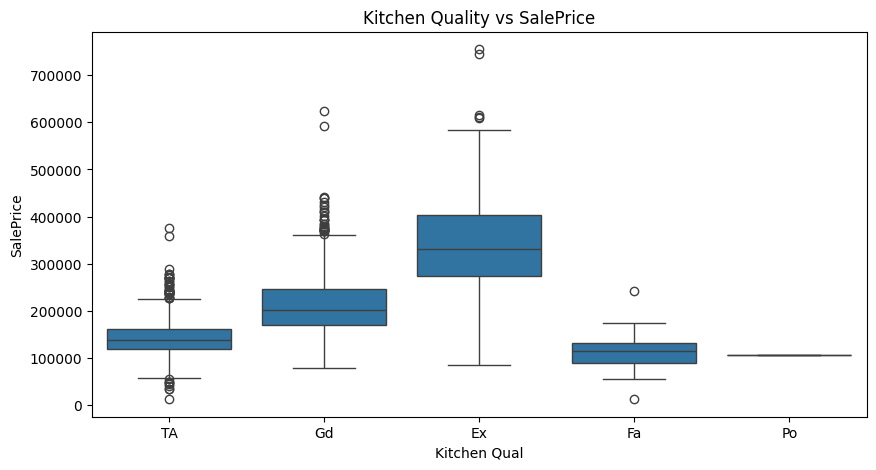

In [ ]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Kitchen Qual",
    y="SalePrice"
)

plt.title("Kitchen Quality vs SalePrice")
plt.show()

In [ ]:
groups = [
    group["SalePrice"].values
    for _, group in df.groupby("Kitchen Qual")
]

f_stat, p_value = f_oneway(*groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)

F-statistic: 651.1132667448521
P-value: 0.0


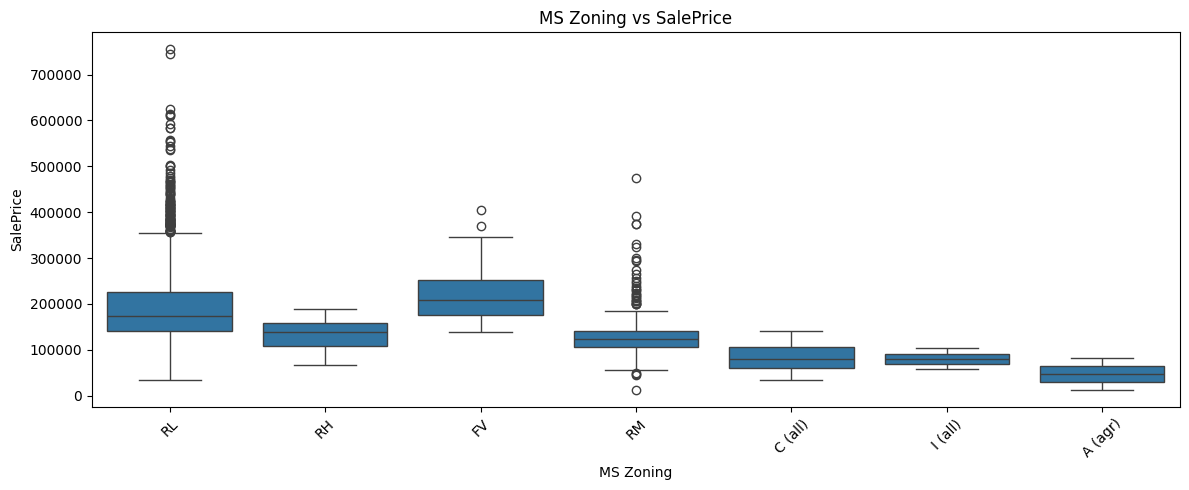

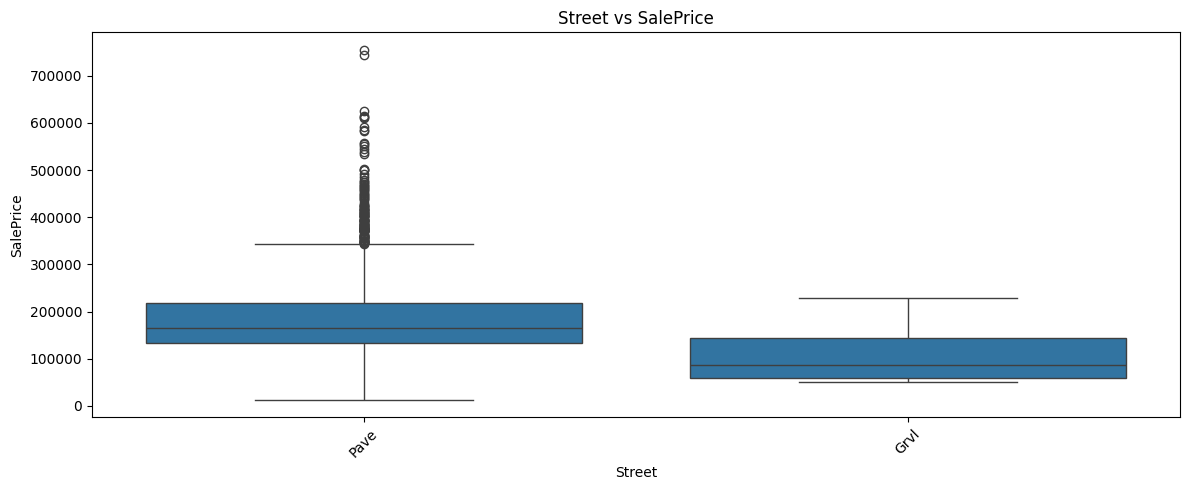

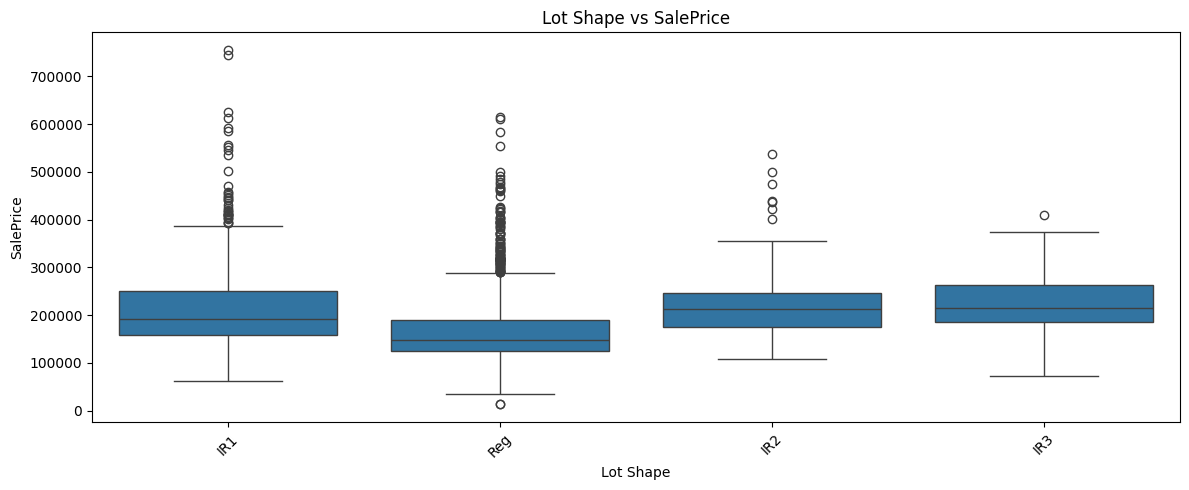

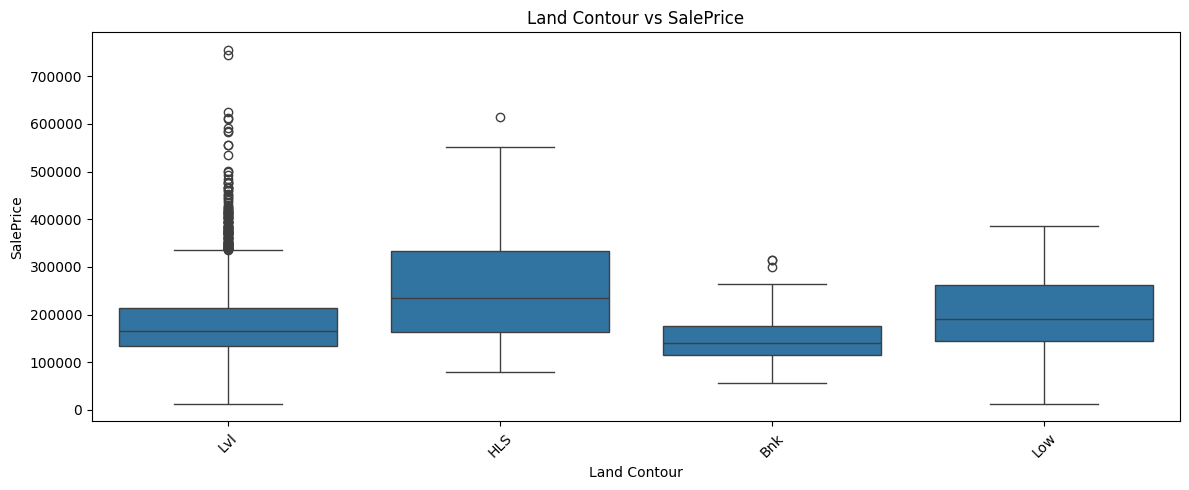

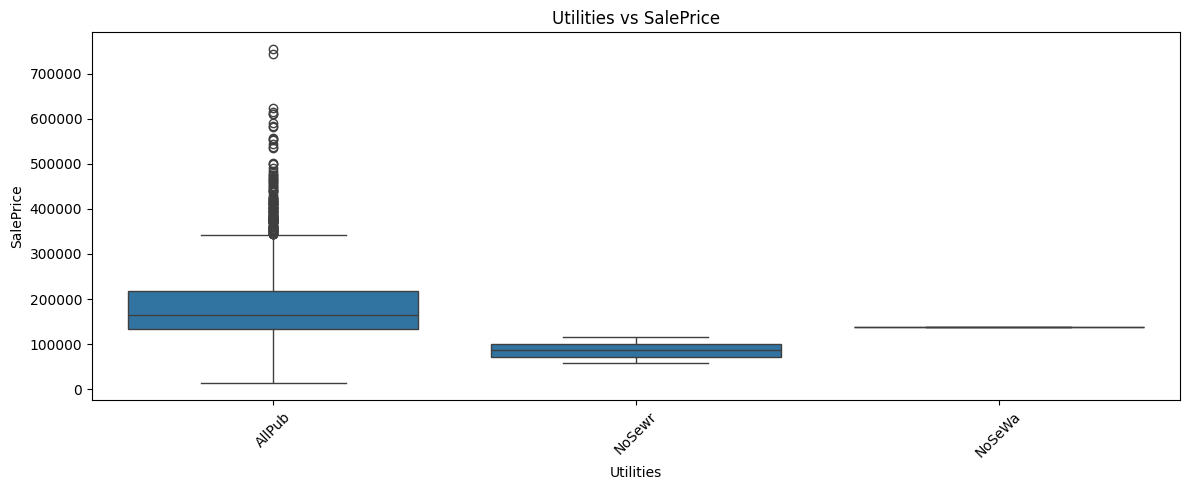

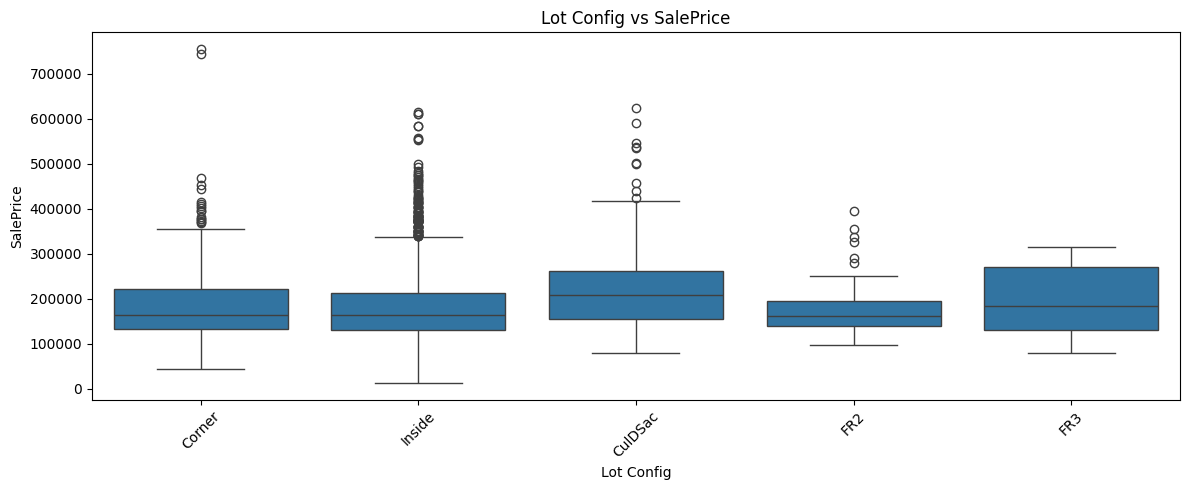

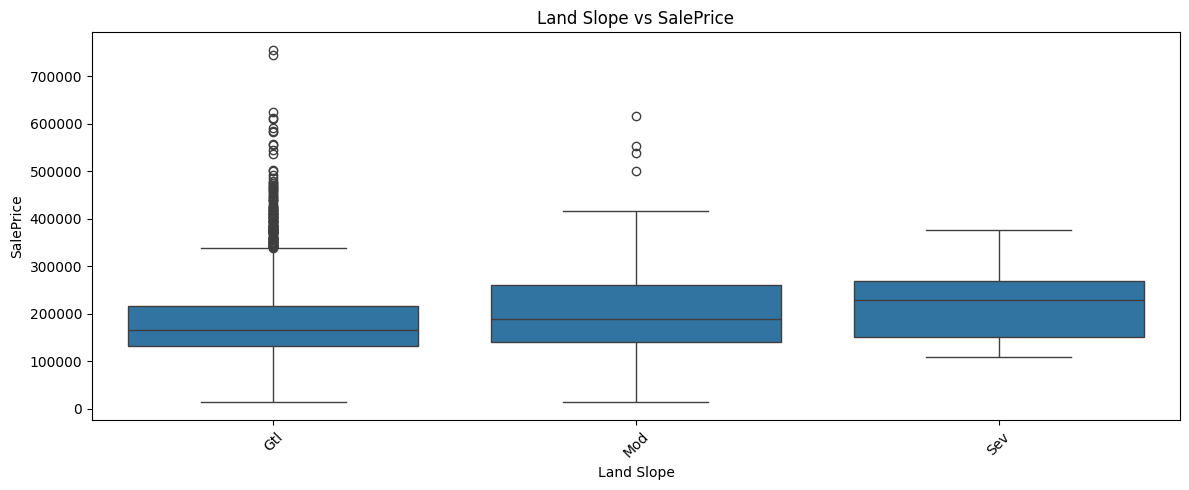

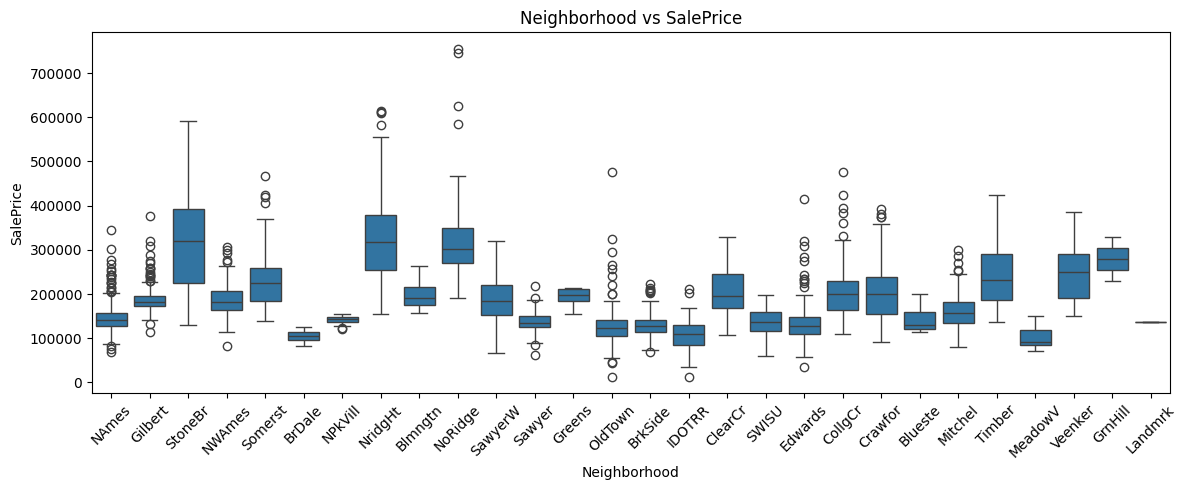

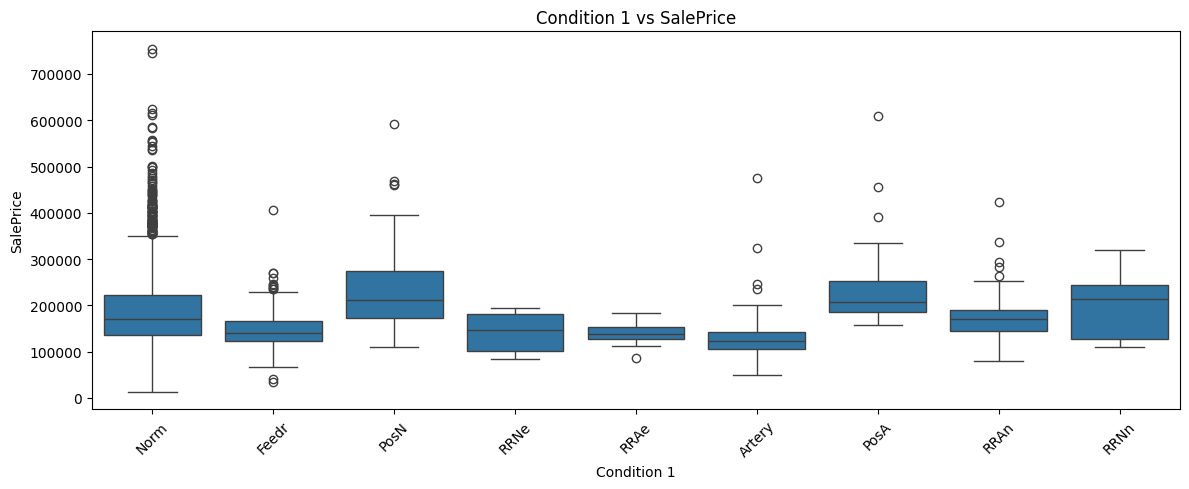

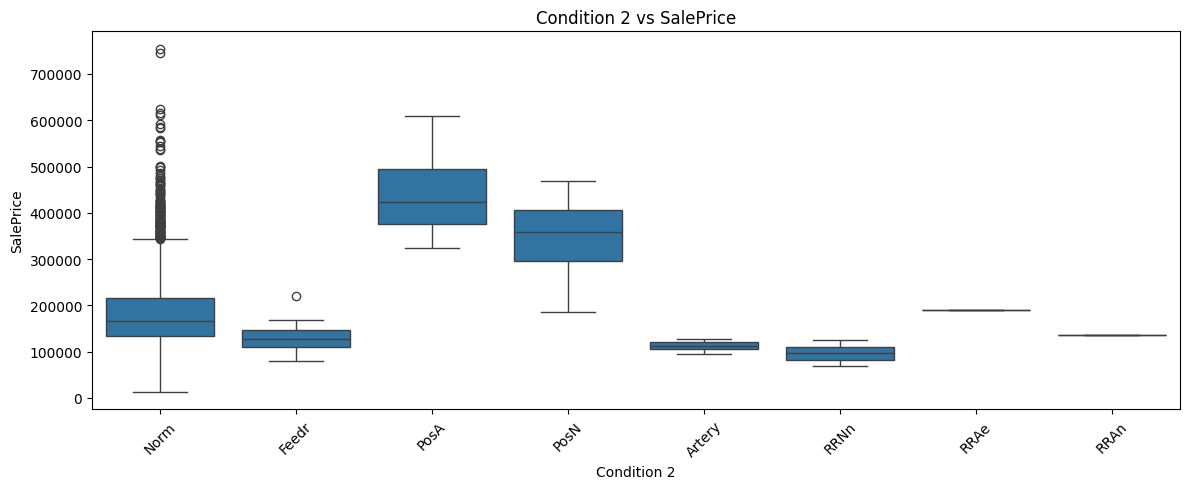

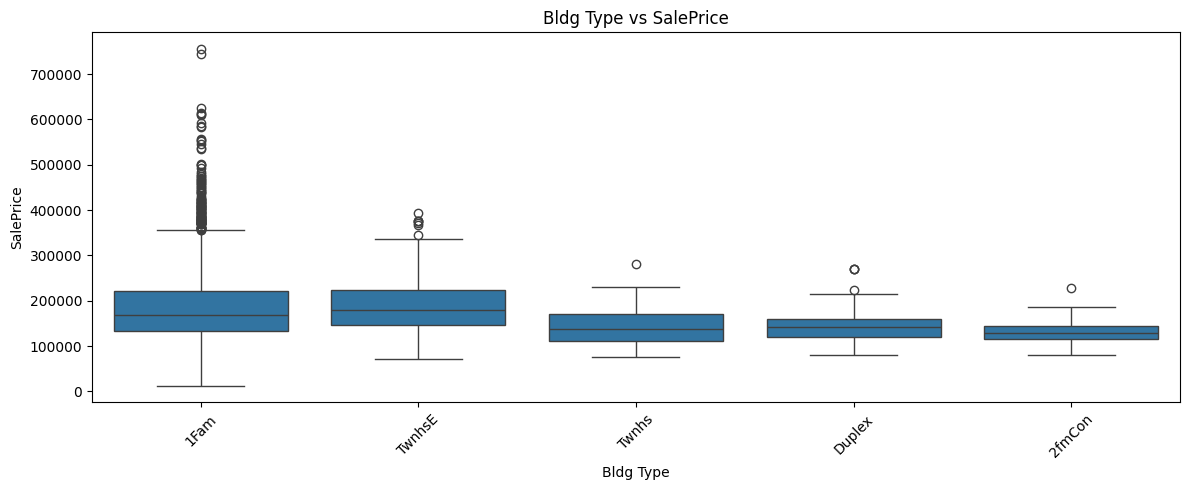

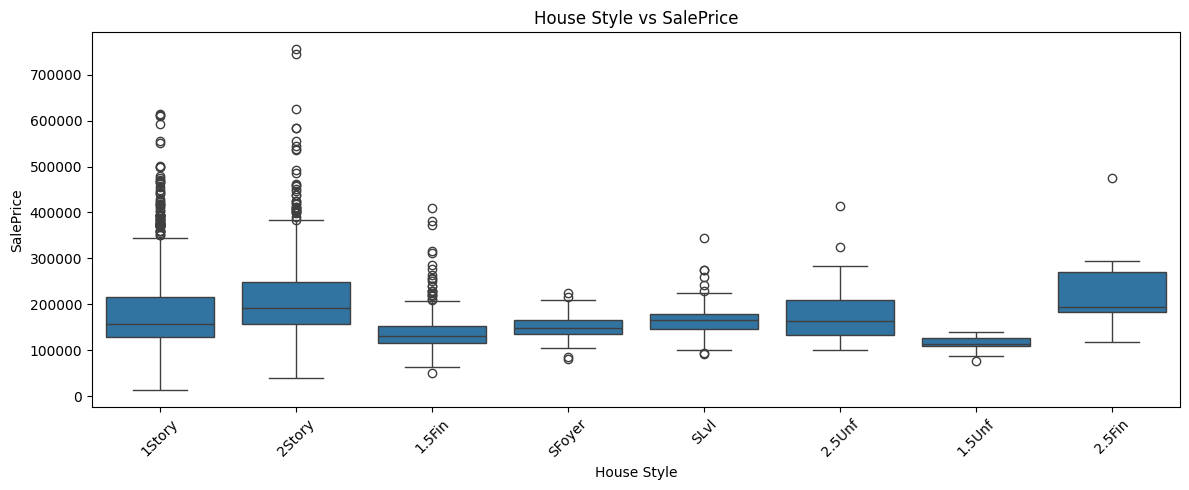

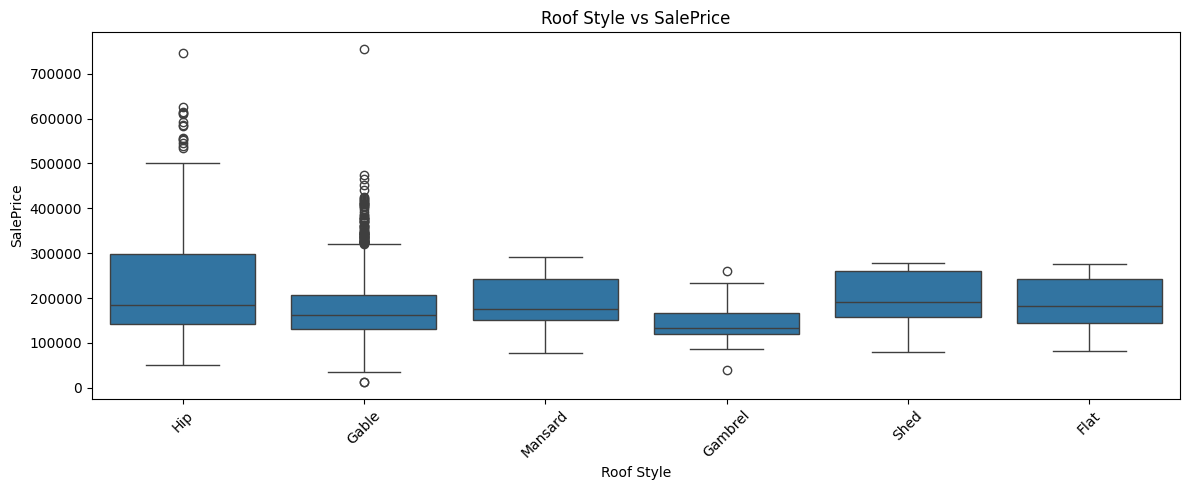

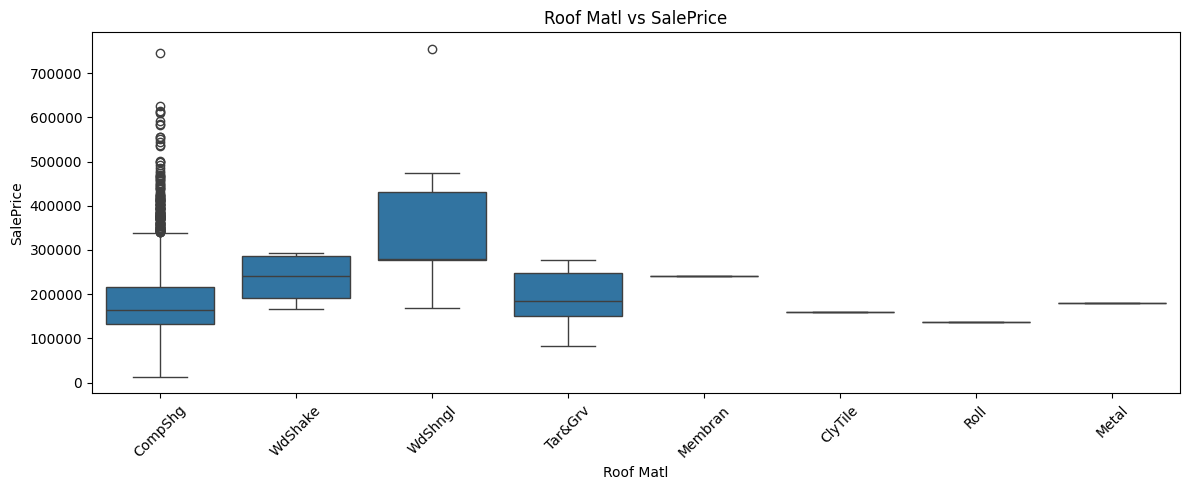

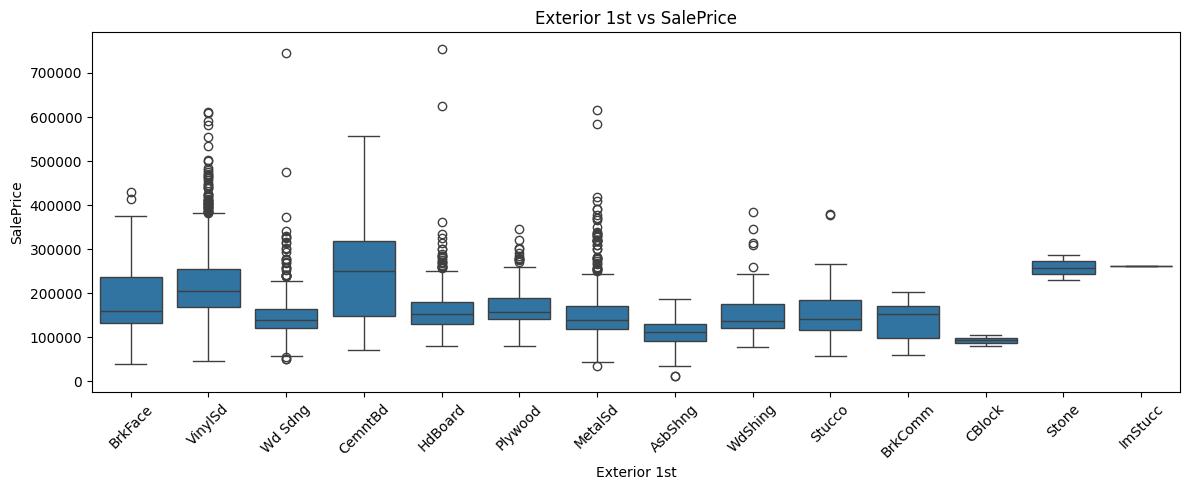

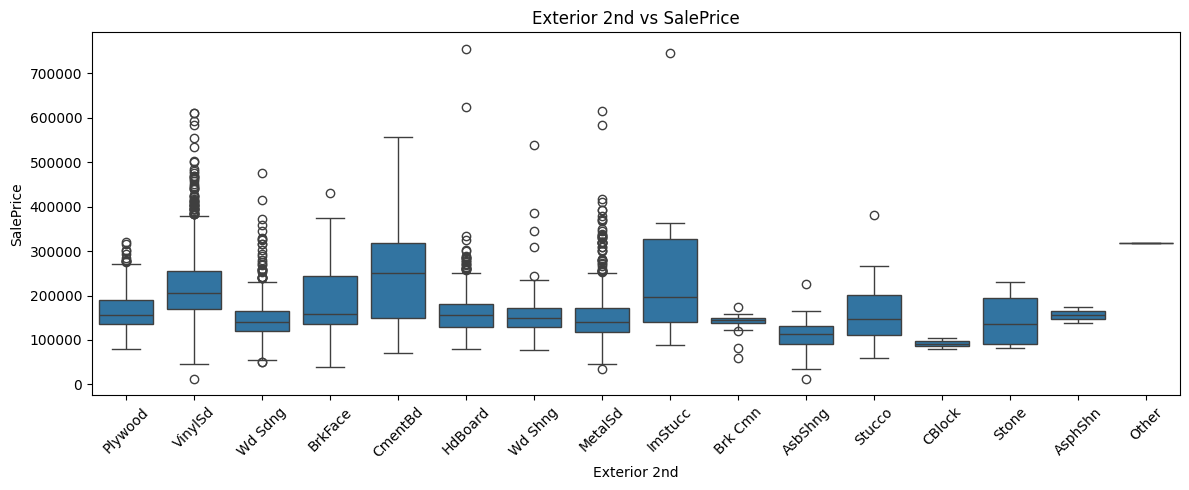

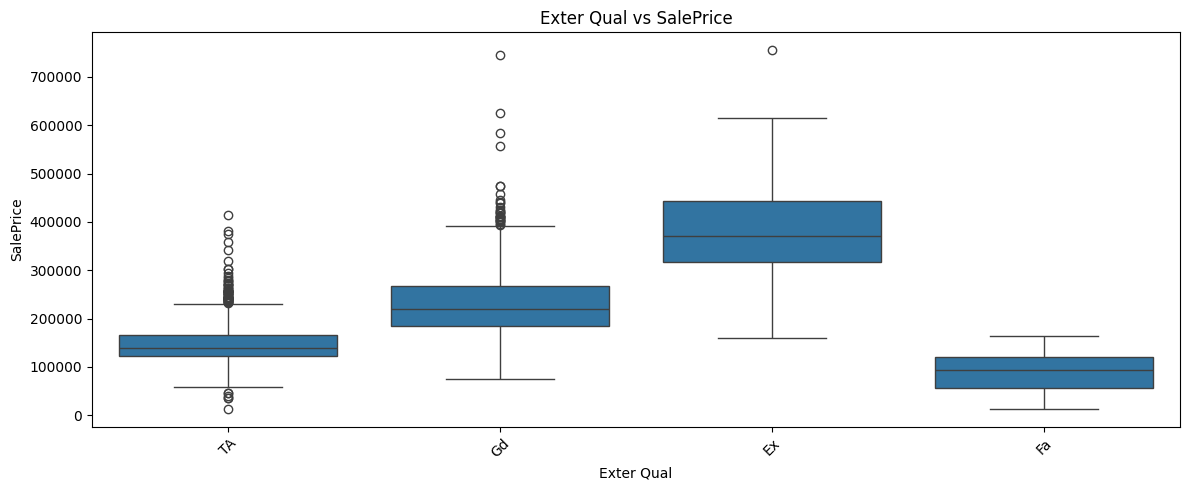

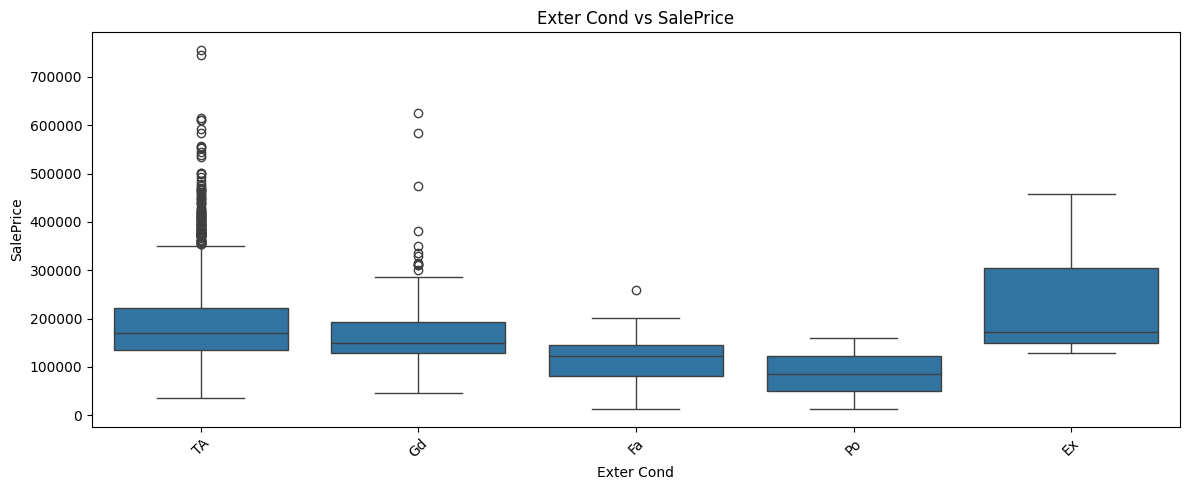

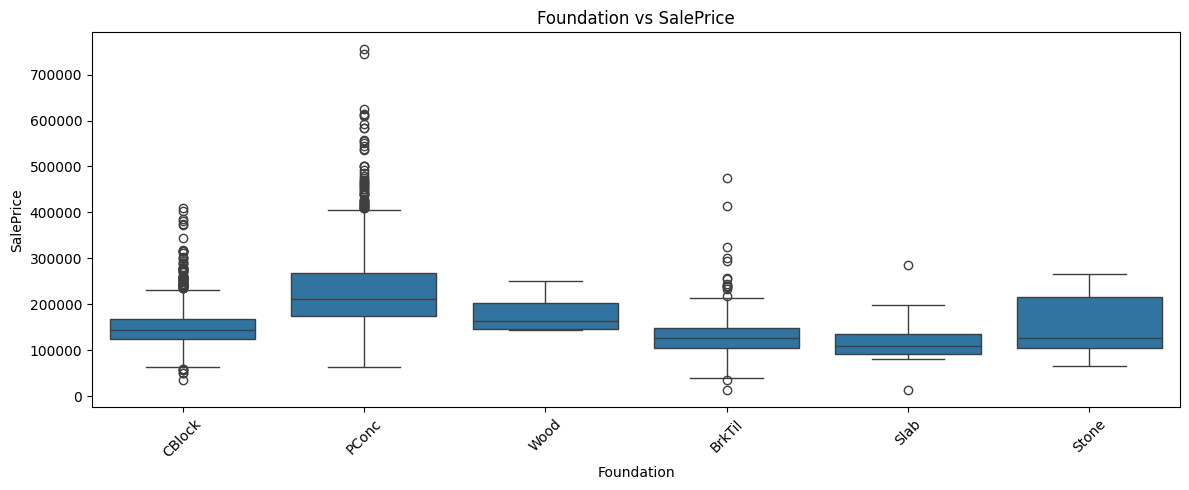

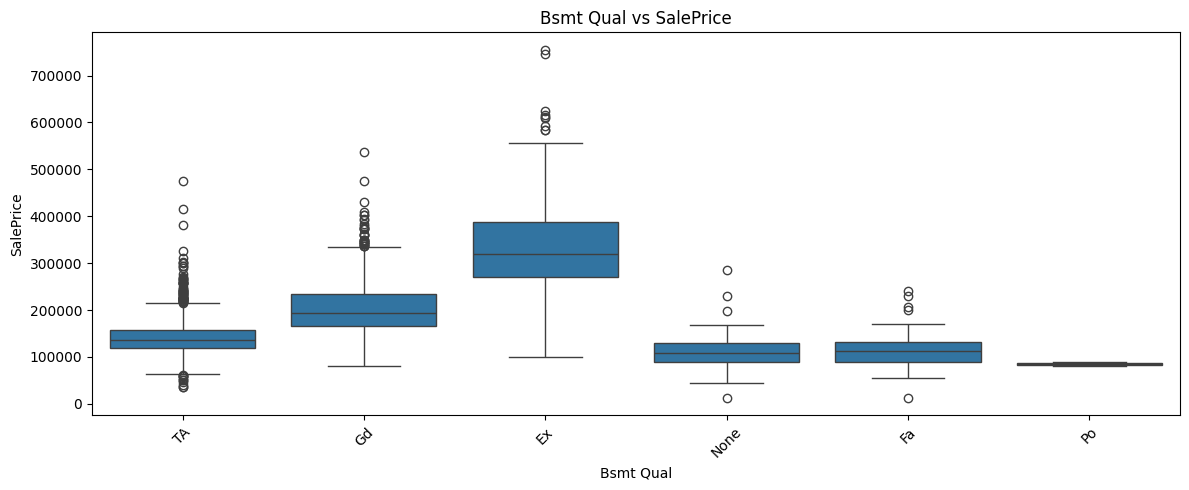

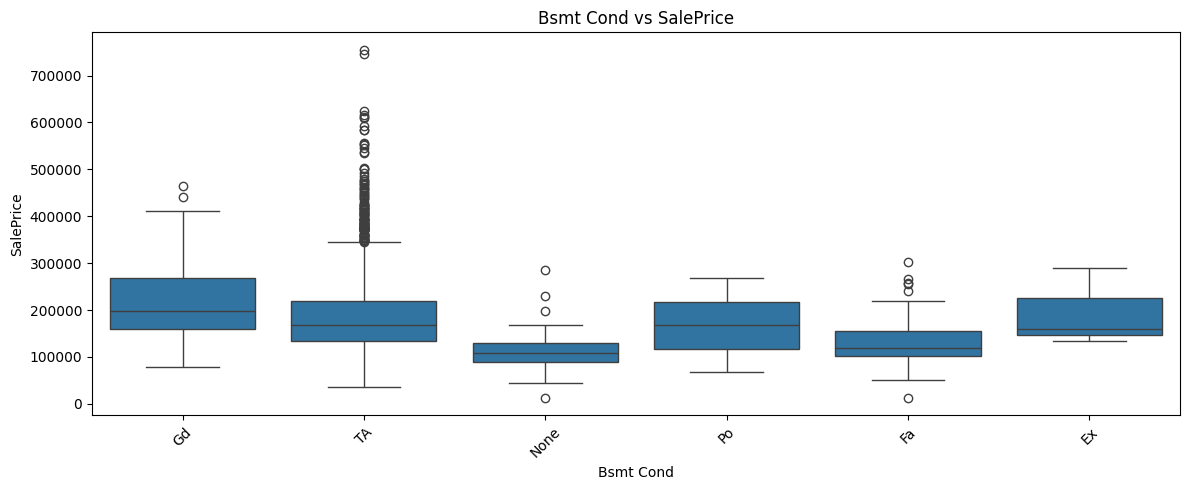

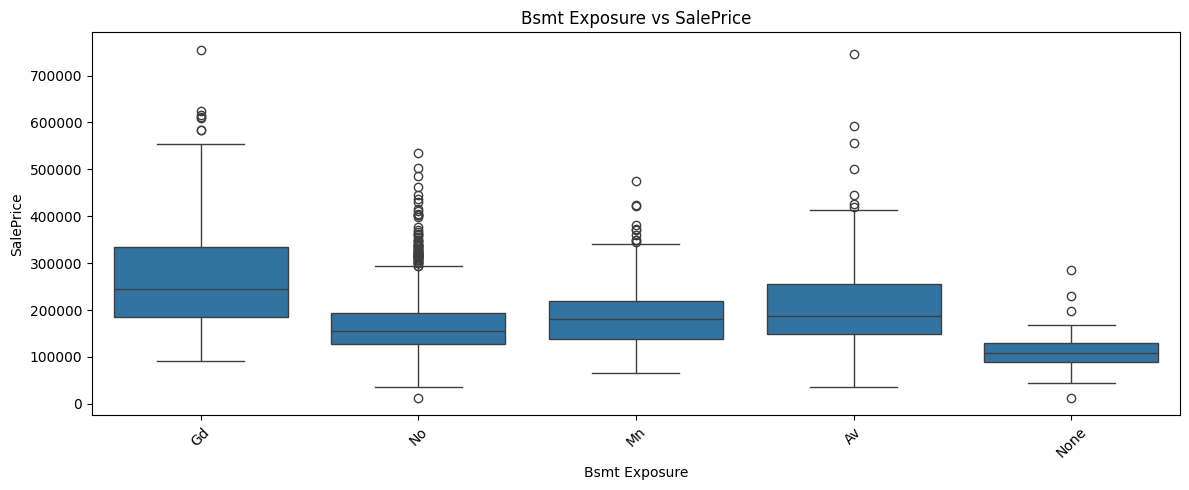

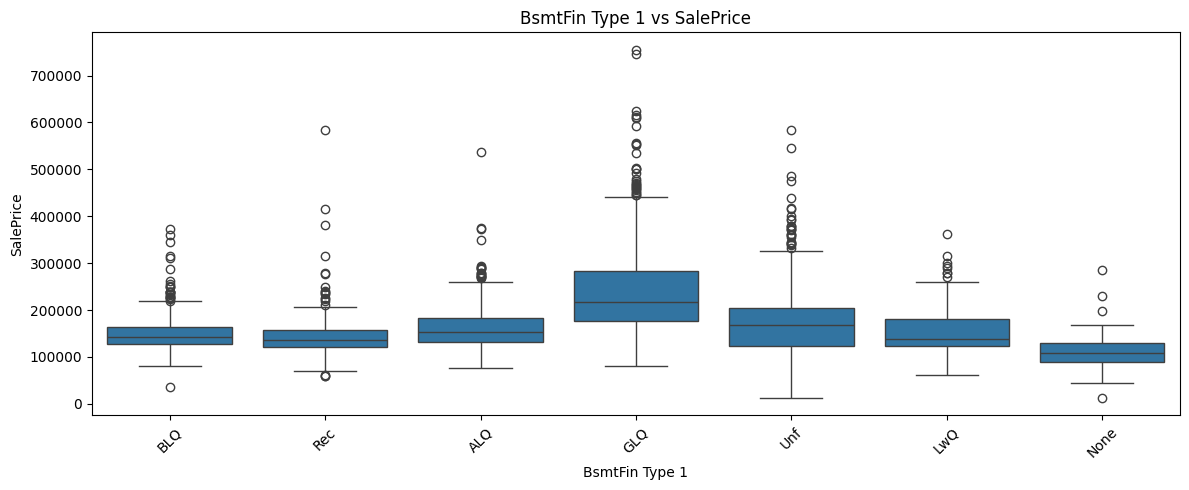

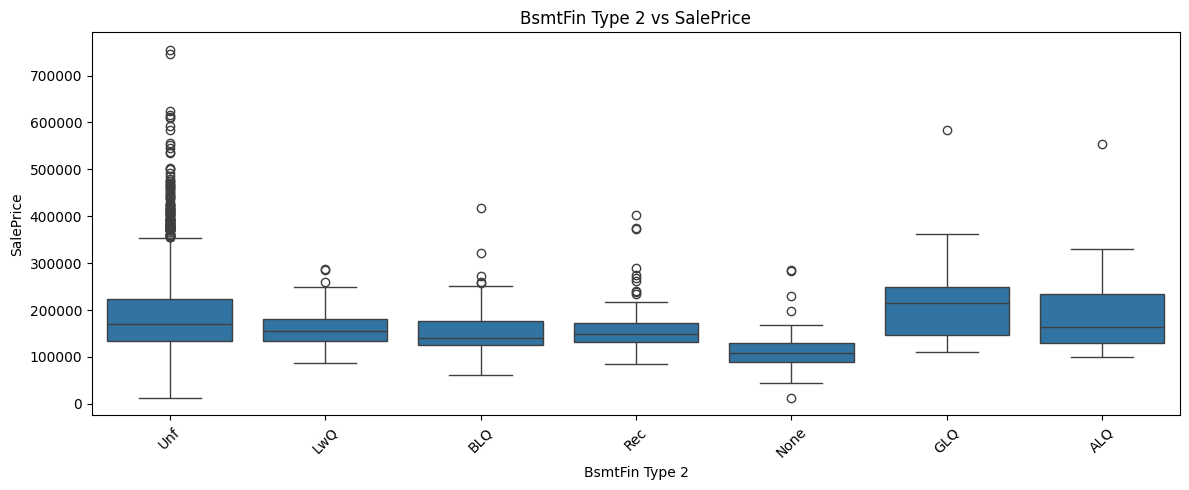

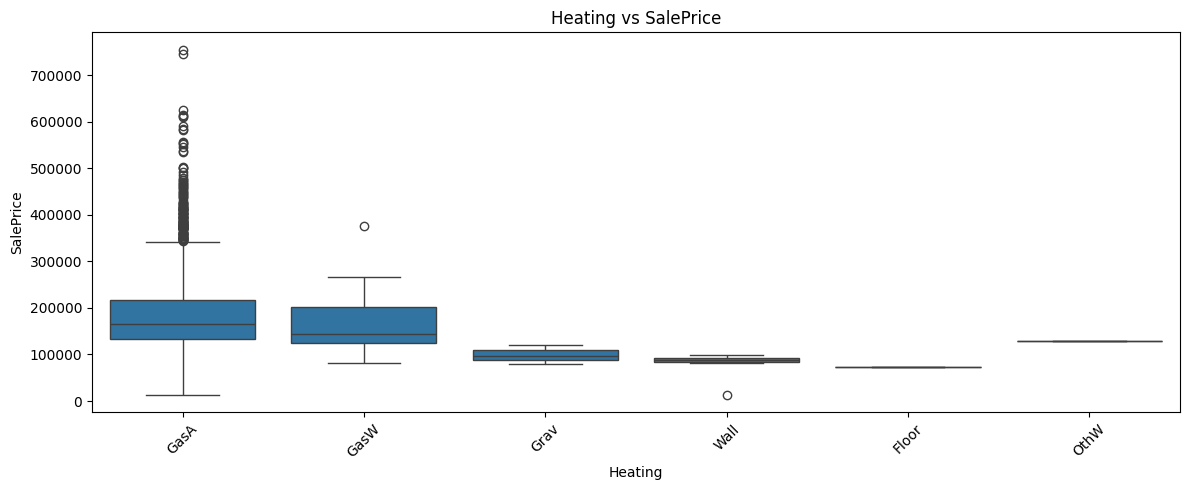

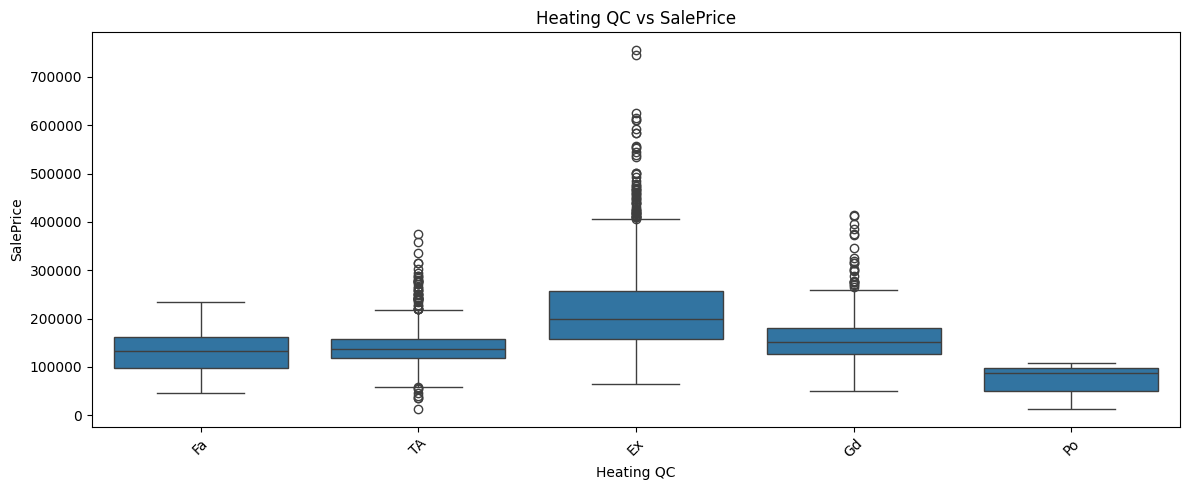

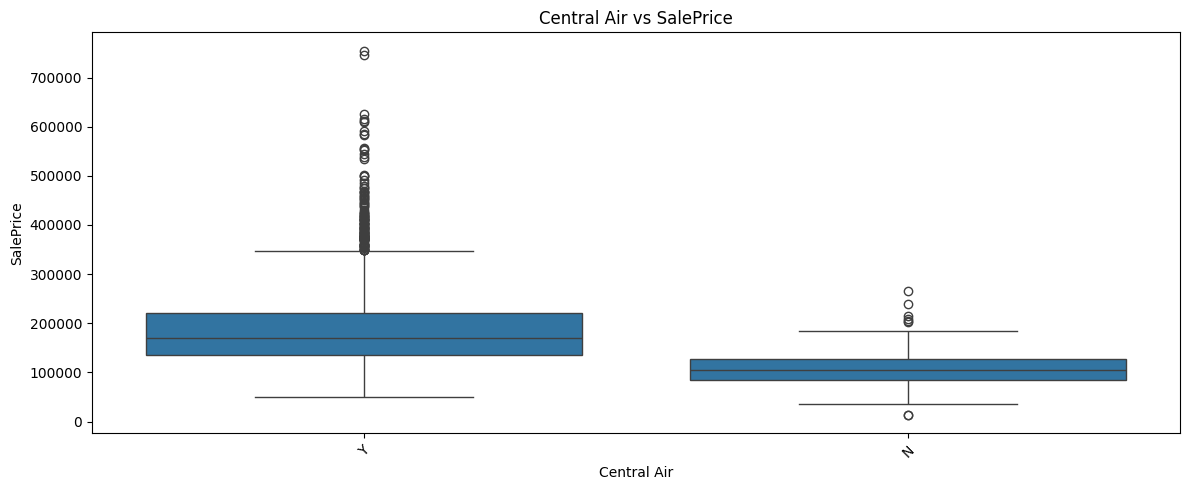

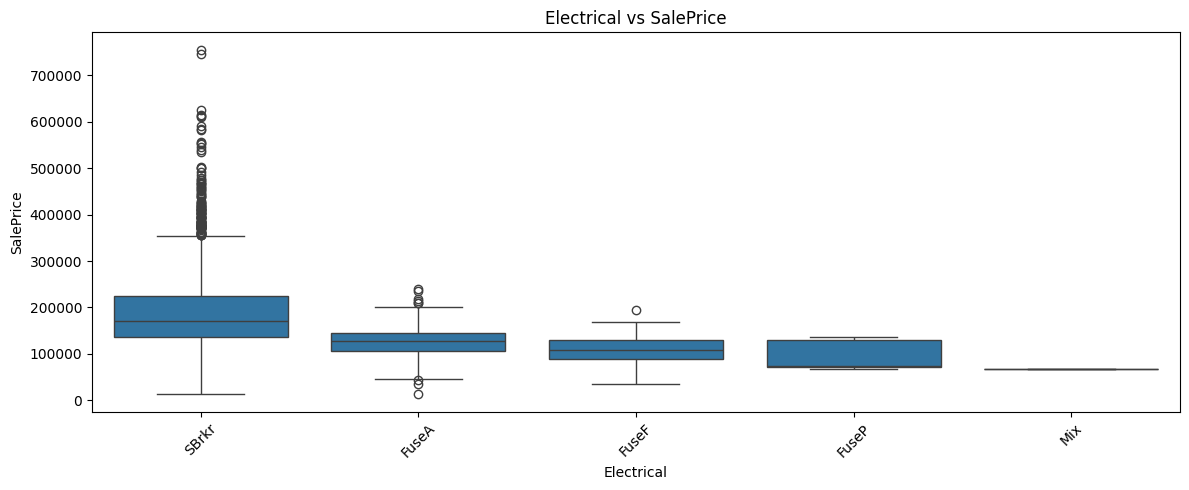

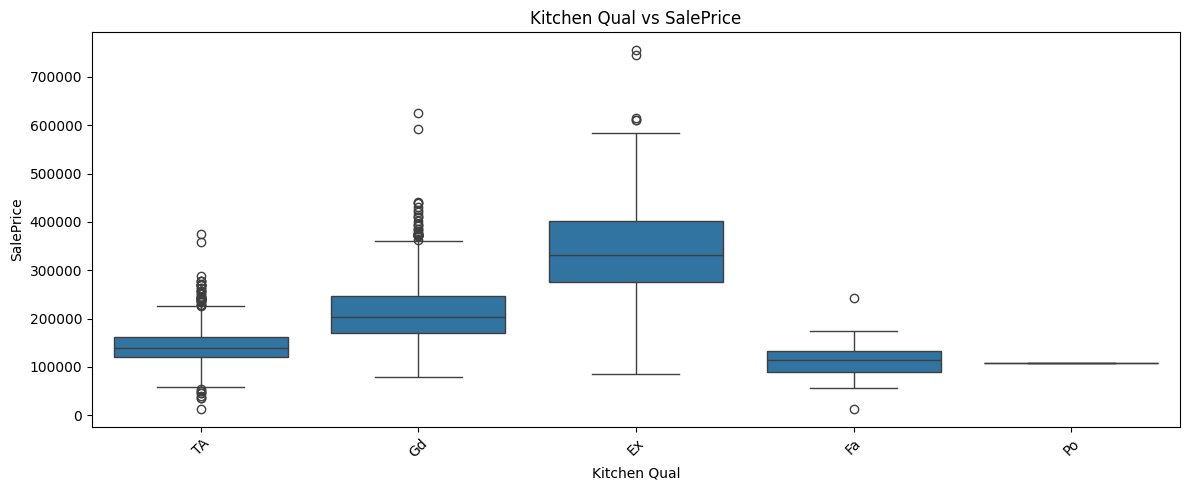

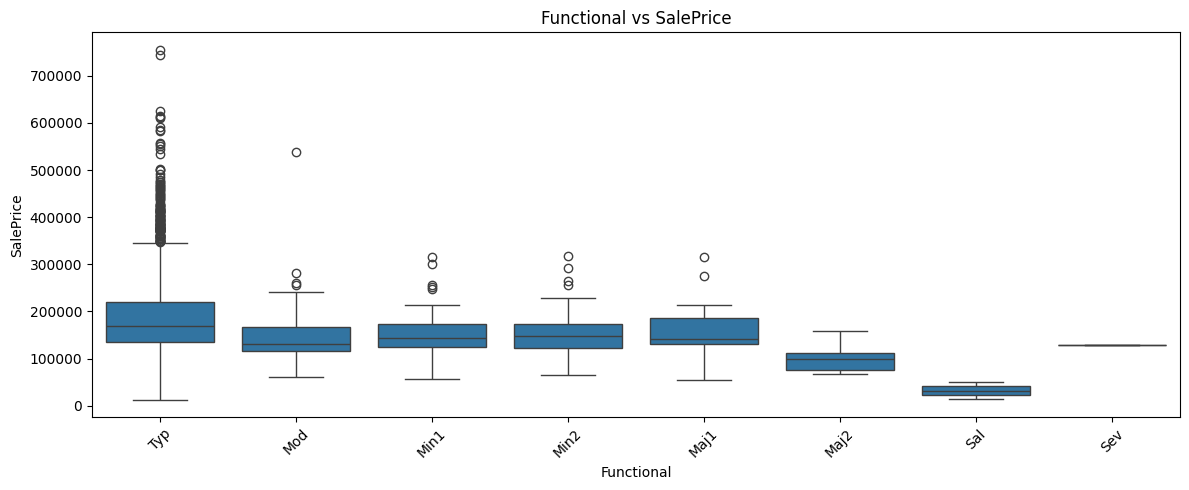

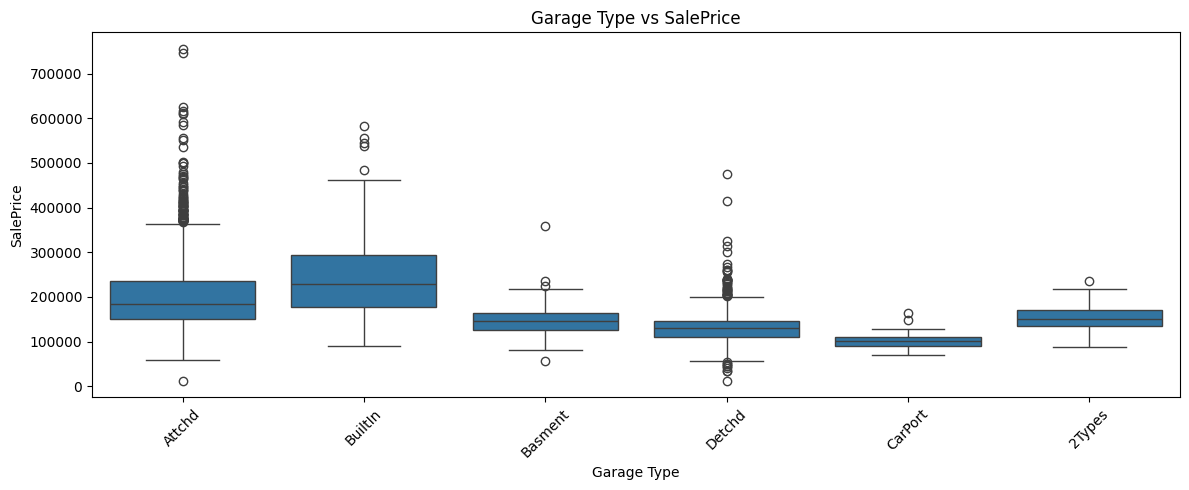

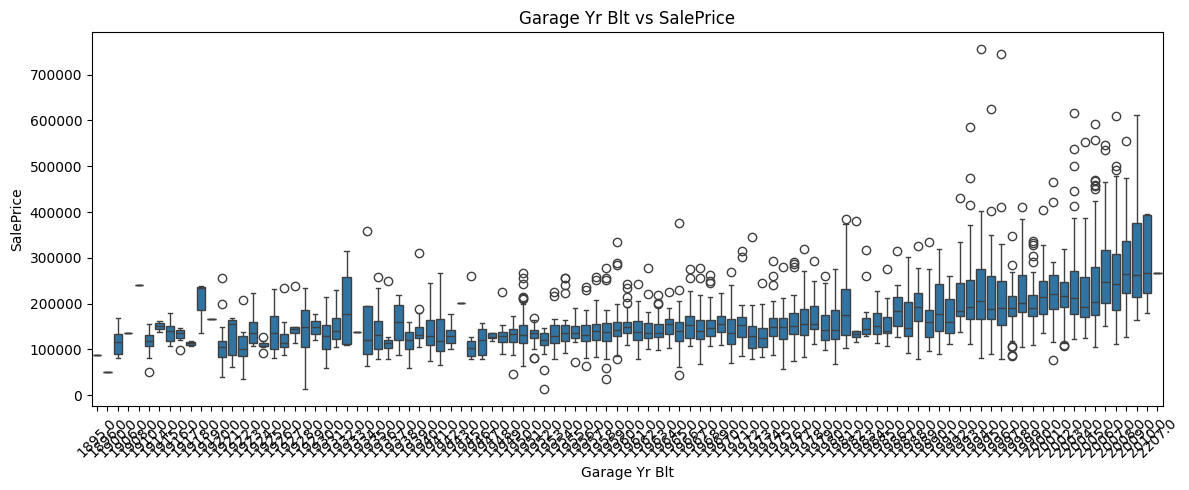

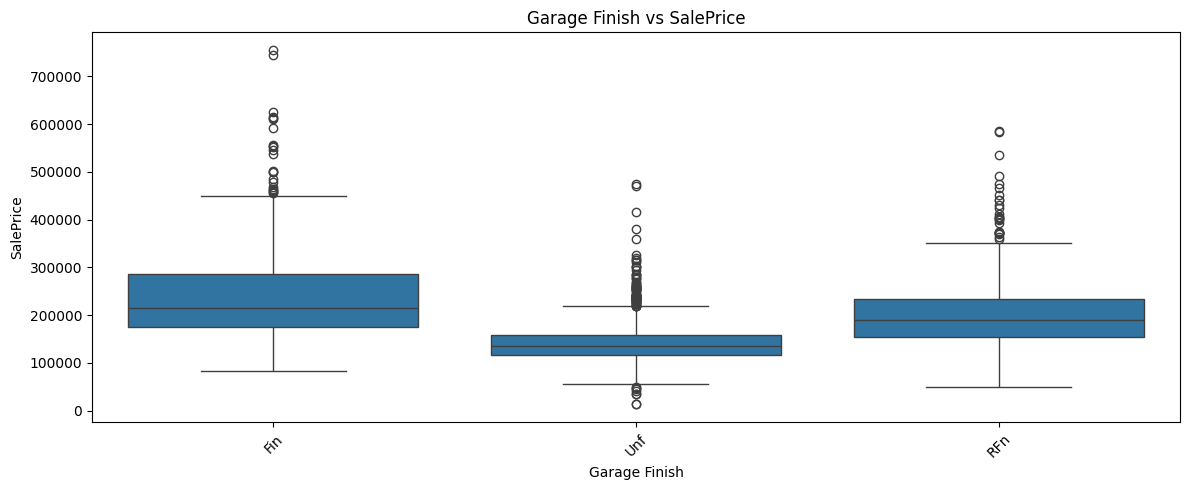

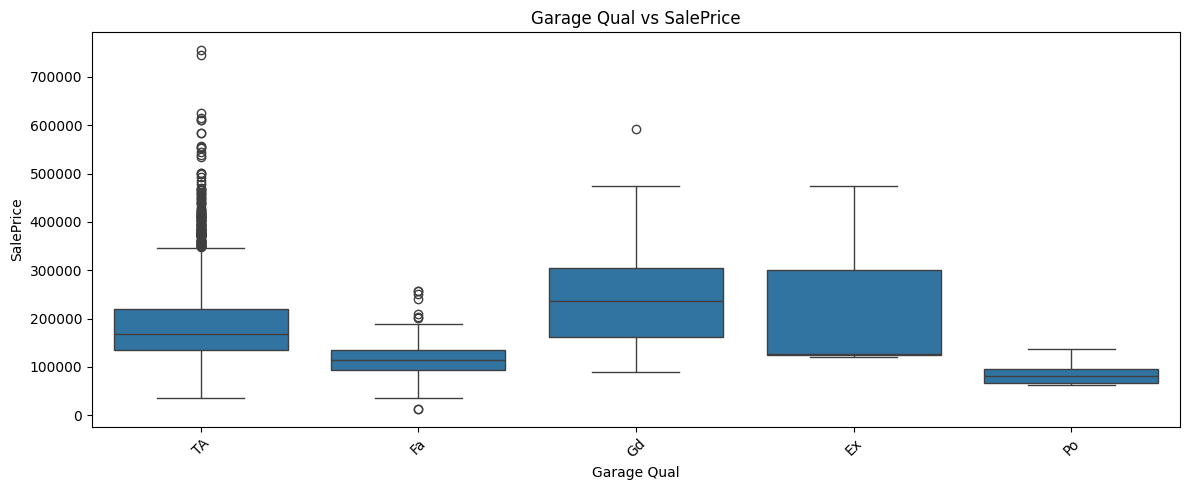

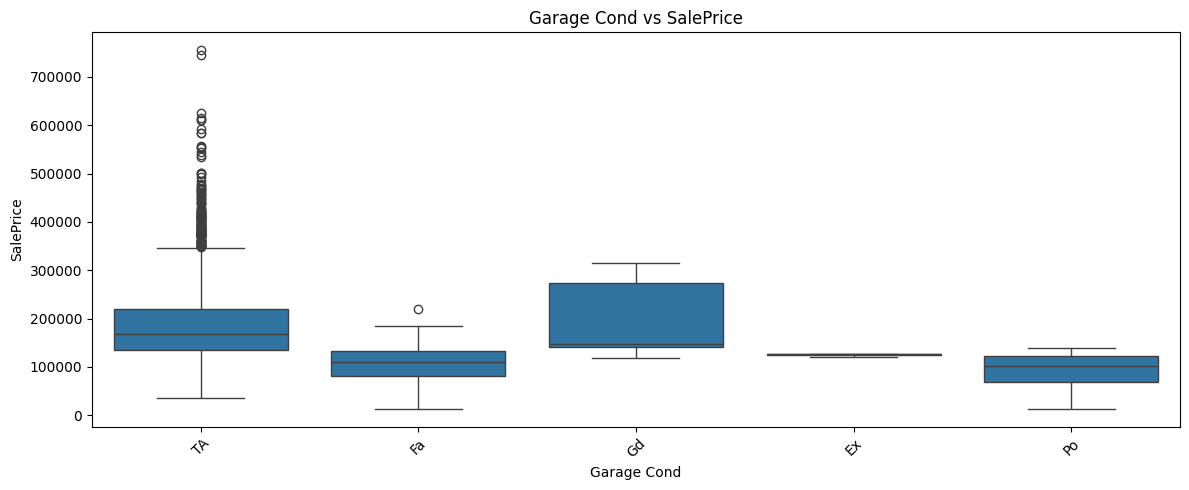

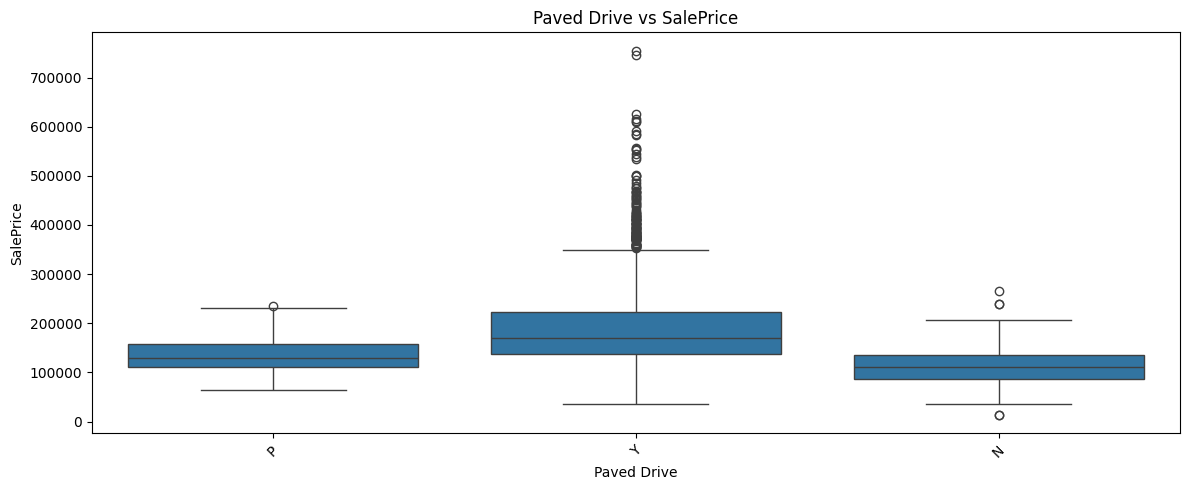

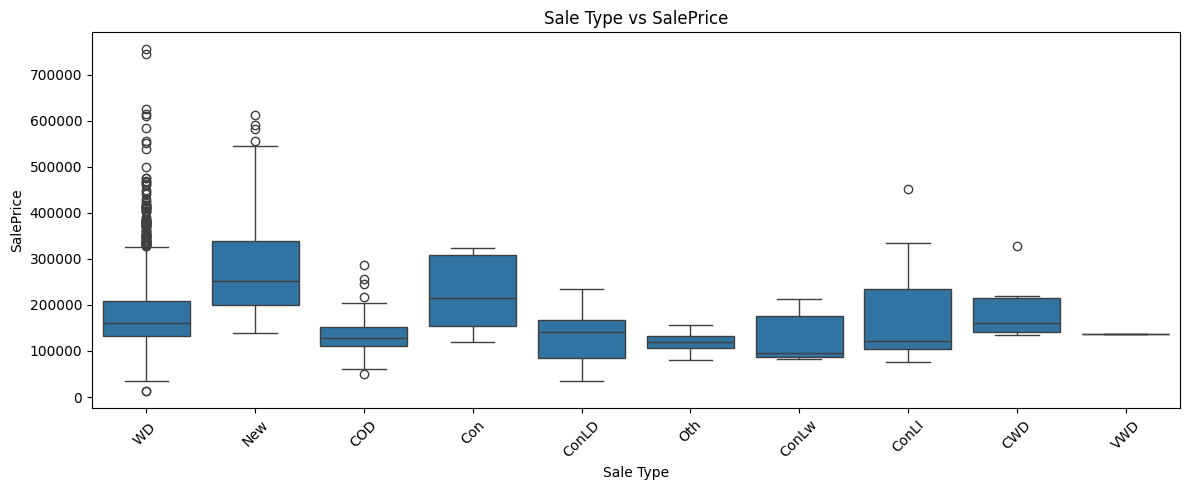

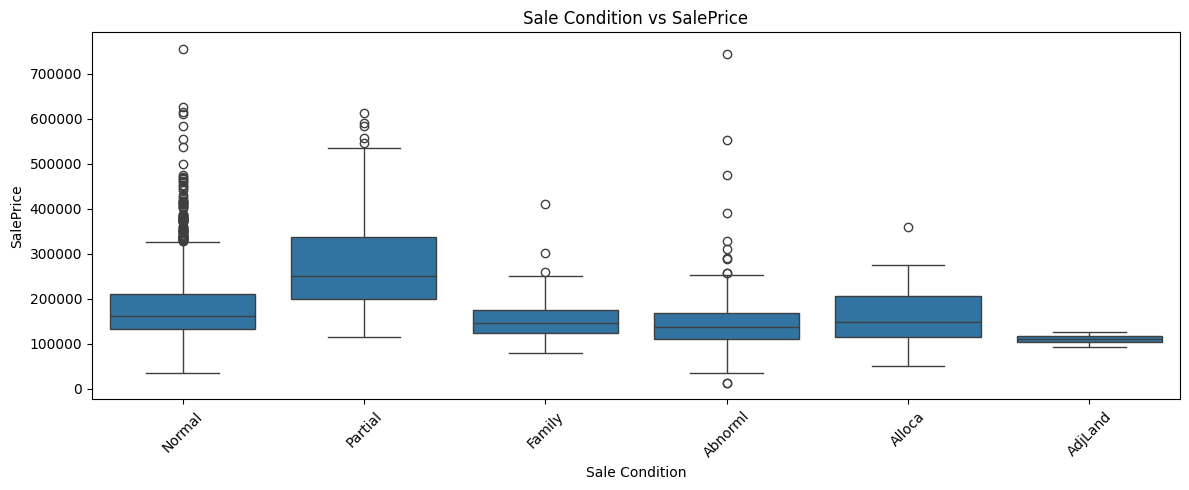

In [ ]:
categorical_features = x_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for col in categorical_features:

    plt.figure(figsize=(12, 5))

    sns.boxplot(
        data=df,
        x=col,
        y="SalePrice"
    )

    plt.title(f"{col} vs SalePrice")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [ ]:
vif_data = pd.DataFrame()

vif_data["Feature"] = numeric_features

vif_data["VIF"] = [
    variance_inflation_factor(
        x_train[numeric_features].values,
        i
    )
    for i in range(x_train[numeric_features].shape[1])
]

vif_data = vif_data.sort_values(
    by="VIF",
    ascending=False
)

print(vif_data)

/tmp/ipykernel_1849/3894545445.py:6: UserWarning: The design matrix is poorly conditioned (condition number=1.03e+16). VIF calculations may be numerically unstable.
  variance_inflation_factor(
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/tmp/ipykernel_1849/3894545445.py:6: UserWarning: The design matrix is poorly conditioned (condition number=1.03e+16). VIF calculations may be numerically unstable.
  variance_inflation_factor(
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/tmp/ipykernel_1849/3894545445.py:6: UserWarning: The design matrix is poorly conditioned (condition number=1.03e+16). VIF calculations may 

            Feature           VIF
9       Bsmt Unf SF  1.000800e+15
8      BsmtFin SF 2  1.000800e+15
13  Low Qual Fin SF  1.000800e+15
12       2nd Flr SF  1.000800e+15
7      BsmtFin SF 1  1.000800e+15
14      Gr Liv Area  1.000800e+15
11       1st Flr SF  1.000800e+15
10    Total Bsmt SF  1.000800e+15
23      Garage Cars  4.469537e+00
21    TotRms AbvGrd  4.179806e+00
24      Garage Area  4.090675e+00
4        Year Built  3.874244e+00
2      Overall Qual  3.036730e+00
17        Full Bath  2.837982e+00
5    Year Remod/Add  2.428850e+00
19    Bedroom AbvGr  2.269171e+00
18        Half Bath  2.215580e+00
15   Bsmt Full Bath  2.165986e+00
22       Fireplaces  1.543658e+00
3      Overall Cond  1.536550e+00
0      Lot Frontage  1.491045e+00
6      Mas Vnr Area  1.393221e+00
20    Kitchen AbvGr  1.363270e+00
1          Lot Area  1.279909e+00
27   Enclosed Porch  1.248084e+00
25     Wood Deck SF  1.235290e+00
26    Open Porch SF  1.222925e+00
16   Bsmt Half Bath  1.168951e+00
30        Pool

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/tmp/ipykernel_1849/3894545445.py:6: UserWarning: The design matrix is poorly conditioned (condition number=1.03e+16). VIF calculations may be numerically unstable.
  variance_inflation_factor(
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/tmp/ipykernel_1849/3894545445.py:6: UserWarning: The design matrix is poorly conditioned (condition number=1.03e+16). VIF calculations may be numerically unstable.
  variance_inflation_factor(
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-defici

In [ ]:
columns_to_remove = [ '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF' ]

df = df.drop(columns=columns_to_remove)
df

,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,...,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,20,RL,141.0,31770,Pave,IR1,Lvl,AllPub,Corner,Gtl,...,0,0,0,0,0,5,2010,WD,Normal,215000
1,20,RH,80.0,11622,Pave,Reg,Lvl,AllPub,Inside,Gtl,...,0,0,120,0,0,6,2010,WD,Normal,105000
2,20,RL,81.0,14267,Pave,IR1,Lvl,AllPub,Corner,Gtl,...,0,0,0,0,12500,6,2010,WD,Normal,172000
3,20,RL,93.0,11160,Pave,Reg,Lvl,AllPub,Corner,Gtl,...,0,0,0,0,0,4,2010,WD,Normal,244000
4,60,RL,74.0,13830,Pave,IR1,Lvl,AllPub,Inside,Gtl,...,0,0,0,0,0,3,2010,WD,Normal,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2924,20,RL,160.0,20000,Pave,Reg,Lvl,AllPub,Inside,Gtl,...,0,0,0,0,0,9,2006,WD,Abnorml,131000
2925,80,RL,37.0,7937,Pave,IR1,Lvl,AllPub,CulDSac,Gtl,...,0,0,0,0,0,3,2006,WD,Normal,142500
2926,20,RL,74.0,8885,Pave,IR1,Low,AllPub,Inside,Mod,...,0,0,0,0,0,6,2006,WD,Normal,131000
2928,20,RL,77.0,10010,Pave,Reg,Lvl,AllPub,Inside,Mod,...,0,0,0,0,0,4,2006,WD,Normal,170000


In [ ]:
df.columns

Index(['MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Street',
       'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope',
       'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type',
       'House Style', 'Overall Qual', 'Overall Cond', 'Year Built',
       'Year Remod/Add', 'Roof Style', 'Roof Matl', 'Exterior 1st',
       'Exterior 2nd', 'Mas Vnr Area', 'Exter Qual', 'Exter Cond',
       'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure',
       'BsmtFin Type 1', 'BsmtFin Type 2', 'Total Bsmt SF', 'Heating',
       'Heating QC', 'Central Air', 'Electrical', 'Gr Liv Area',
       'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath',
       'Bedroom AbvGr', 'Kitchen AbvGr', 'Kitchen Qual', 'TotRms AbvGrd',
       'Functional', 'Fireplaces', 'Garage Type', 'Garage Yr Blt',
       'Garage Finish', 'Garage Cars', 'Garage Area', 'Garage Qual',
       'Garage Cond', 'Paved Drive', 'Wood Deck SF', 'Open Porch SF',
       'Enclosed Porch', '3Ssn P

In [ ]:
# Select only numeric columns from df (excluding non-numeric columns and target if present)
numeric_df = df.select_dtypes(include=["int64", "float64"])
if "SalePrice" in numeric_df.columns:
    numeric_df = numeric_df.drop(columns=["SalePrice"])

X_vif_constant = sm.add_constant(numeric_df)

# Calculate VIF
vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif_constant.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif_constant.values, i)
    for i in range(X_vif_constant.shape[1])
]

vif_data = vif_data.sort_values(by="VIF", ascending=False)
vif_data

,Feature,VIF
10,Gr Liv Area,6.516140
19,Garage Cars,4.435302
17,TotRms AbvGrd,4.219861
20,Garage Area,4.050943
6,Year Built,3.856307
4,Overall Qual,3.036138
13,Full Bath,2.822665
7,Year Remod/Add,2.394548
9,Total Bsmt SF,2.378589
15,Bedroom AbvGr,2.246040


In [ ]:
# Numerical features with stronger relationships
strong_moderate_features = [
    'Overall Qual',
    'Gr Liv Area',
    'Garage Cars',
    'Total Bsmt SF',
    'Garage Area',
    '1st Flr SF',
    'Full Bath',
    'Year Built',
    'Year Remod/Add',
    'TotRms AbvGrd',
    'Mas Vnr Area',
    'Fireplaces',
    'BsmtFin SF 1',
    'Lot Frontage',
    'Wood Deck SF',
    'Open Porch SF',
    '2nd Flr SF',
    'Bsmt Full Bath',
    'Half Bath',
    'Lot Area',
    'Bsmt Unf SF',
    'Bedroom AbvGr',
    'Screen Porch',
    'Pool Area'
]

# Weak and near-zero correlated features
weak_features = [
    'Mo Sold',
    '3Ssn Porch',
    'BsmtFin SF 2',
    'Misc Val',
    'Bsmt Half Bath',
    'Yr Sold',
    'Low Qual Fin SF',
    'Kitchen AbvGr',
    'Enclosed Porch',
    'Overall Cond'
]

# Categorical features used in both models
categorical_features = [
    'MS SubClass',
    'Neighborhood',
    'Kitchen Qual',
    'House Style',
    'Garage Type',
    'Foundation',
    'Exterior 1st',
    'Bsmt Qual',
    'Heating QC',
    'Central Air',
    'Exter Qual'
]

In [ ]:
# Model A: Keep all numerical features (filtered to match existing columns in df)
features_A = [
    col for col in (strong_moderate_features + weak_features + categorical_features)
    if col in df.columns
]

# Model B: Remove weak and near-zero numerical features (filtered to match existing columns in df)
features_B = [
    col for col in (strong_moderate_features + categorical_features)
    if col in df.columns
]

XA = df[features_A].copy()
XB = df[features_B].copy()

y = df['SalePrice'].copy()

In [ ]:
XA_train, XA_test, y_train, y_test = train_test_split(
    XA,
    y,
    test_size=0.2,
    random_state=42
)

XB_train, XB_test, _, _ = train_test_split(
    XB,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
def create_pipeline(X):

    numerical_cols = X.select_dtypes(
        include=['number']
    ).columns.tolist()

    categorical_cols = X.select_dtypes(
        include=['object', 'category', 'bool']
    ).columns.tolist()

    numerical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ])

    preprocessor = ColumnTransformer([
        ('numerical', numerical_pipeline, numerical_cols),
        ('categorical', categorical_pipeline, categorical_cols)
    ])

    model_pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', LinearRegression())
    ])

    return model_pipeline

In [ ]:
model_A = create_pipeline(XA_train)
model_B = create_pipeline(XB_train)

model_A.fit(XA_train, y_train)
model_B.fit(XB_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Overall Qual',
                                                   'Gr Liv Area', 'Garage Cars',
                                                   'Total Bsmt SF',
                                                   'Garage Area', 'Full Bath',
                                                   'Year Built',
                                                   'Year Remod/Add',
                                                   'TotRms AbvGrd',
                                                   'Mas Vnr Area', 'Fireplaces',
                                                   'Lot Frontage',
                                                   'Wood Deck SF',
                                                   'Open Por...
                                                   'Bedroom AbvGr',
                                                   'Screen Porch', 'Pool Area',
                                                   'MS SubClass']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Neighborhood',
                                                   'Kitchen Qual',
                                                   'House Style', 'Garage Type',
                                                   'Foundation', 'Exterior 1st',
                                                   'Bsmt Qual', 'Heating QC',
                                                   'Central Air',
                                                   'Exter Qual'])])),
                ('regressor', LinearRegression())])

In [ ]:
def evaluate_model(model, X_test, y_test):

    predictions = model.predict(X_test)

    return {
        'MAE': mean_absolute_error(y_test, predictions),
        'RMSE': np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        'R2 Score': r2_score(y_test, predictions)
    }


results_A = evaluate_model(model_A, XA_test, y_test)
results_B = evaluate_model(model_B, XB_test, y_test)

comparison = pd.DataFrame(
    [results_A, results_B],
    index=['Model A - All Features', 'Model B - Without Near-Zero']
)

print(comparison.round(3))

                                   MAE       RMSE  R2 Score
Model A - All Features       17392.921  30473.742     0.866
Model B - Without Near-Zero  17996.414  31177.455     0.860


In [ ]:
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [ ]:
model_a = create_pipeline(XA)
model_b = create_pipeline(XB)

In [ ]:
scores_A = cross_validate(
    model_A,
    XA,
    y,
    cv=kfold,
    scoring={
        'MAE': 'neg_mean_absolute_error',
        'RMSE': 'neg_root_mean_squared_error',
        'R2': 'r2'
    },
    return_train_score=False
)

In [ ]:
scores_B = cross_validate(
    model_B,
    XB,
    y,
    cv=kfold,
    scoring={
        'MAE': 'neg_mean_absolute_error',
        'RMSE': 'neg_root_mean_squared_error',
        'R2': 'r2'
    },
    return_train_score=False
)

In [ ]:
comparison = pd.DataFrame({
    'Model A - All Features': [
        -scores_A['test_MAE'].mean(),
        -scores_A['test_RMSE'].mean(),
        scores_A['test_R2'].mean()
    ],

    'Model B - Without Near-Zero': [
        -scores_B['test_MAE'].mean(),
        -scores_B['test_RMSE'].mean(),
        scores_B['test_R2'].mean()
    ]
}, index=['MAE', 'RMSE', 'R2 Score'])

print(comparison.round(3))

          Model A - All Features  Model B - Without Near-Zero
MAE                    17527.462                    18031.244
RMSE                   29833.116                    29741.054
R2 Score                   0.859                        0.859
